# Ієрархічна беєсівська модель простору станів для деградації шин F1 (2022–2024) — відтворюваний notebook редакції (v1.1)

**Призначення.** Обчислювальна основа доопрацювання статті після рецензування: реалізація основної моделі та її альтернативних специфікацій, діагностика MCMC, апріорні й апостеріорні предиктивні перевірки, PSIS-LOO, дослідження відновлення параметрів на синтетичних даних, реєстр експериментів, часово коректна прогнозна перевірка, автоматичне формування рисунків, таблиць статті та матеріалів для відповіді рецензентам.

**Як користуватись.**
1. Покладіть `f1_cache_combined_2022_2024.csv` у `data/` (для `SMOKE` не потрібно — синтетичні дані).
2. Виставте режим у комірці конфігурації нижче (`MODE`): `SMOKE` (хвилини, синтетика, перевірка всього ланцюжка), `PILOT` (3 траси, реальні дані, оцінка часу), `FULL` (усі дані), `REPORT_ONLY` (без MCMC: діагностика, предиктивні перевірки, LOO, прогноз, таблиці й рисунки для всіх уже завершених оцінювань).
3. `Kernel → Restart & Run All`. **Після вимкнення світла: просто запустіть `Run All` знову** (або `python scripts/run_pipeline.py --mode FULL`). Усі завершені етапи пропускаються, незавершене оцінювання продовжується з останнього зафіксованого checkpoint (повний стан sampler, без повторної адаптації; втрата — щонайбільше `checkpoint_every` переходів).

**Чесність результатів.** Жодне число в цьому notebook не вписане вручну: усі значення, таблиці й підписи походять зі збереженого запуску (`outputs/<mode>/`), позначеного run ID. Стан кожної специфікації («реалізовано», «запущено», «завершено», «пройшла діагностику») визначається за сховищем checkpoint-ів, а не за конфігурацією. Режими `SMOKE`/`PILOT` **не** дають результатів для статті.

## Редакція v1.1: що змінено в цьому файлі та як читати його виходи

* **Виходи комірок, виконаних у запуску `FULL-2483ee9f` (код v1.0), збережено без змін** — це протокол уже проведених обчислень (вісім оцінювань, ≈ 40 год вибіркового етапу MCMC). Код v1.1 відтворює той самий run ID і ті самі ідентифікатори всіх восьми оцінювань (`tests/rev2/test_rev2_fingerprint_compat.py`), тому повторювати їх **не потрібно**: достатньо `MODE = "REPORT_ONLY"`.
* **Змінено код комірок** (перший рядок кожної містить позначку `[v1.1]`): конфігурація — черга оцінювань задається `cfg.fits_override`, а не вилученням специфікацій із реєстру (інакше невиконані експерименти зникали зі звітів); preflight, prior predictive і діагностика — `pl.primary_experiment()` замість «першого в черзі»; звіт — нові стовпці `experiments_status.csv`.
* **Комірки з позначкою `[v1.1, нове]`** додано в цій редакції. У цьому файлі вони **не виконувалися** (виходів немає) і не запускають MCMC, якщо прямо не сказано інше.
* Вихід комірки зі звітами (розділ 8) сформовано кодом v1.0: там стара матриця відповіді з кодами `R2.x`. Чинна матриця з кодами рецензії `A1–A16`, `B1–B5`, `E1–E3` — у `docs/REVIEWER_RESPONSE_uk.md` і (після `REPORT_ONLY`) у `reports/reviewer_response_matrix.md`.
* `config.yaml` тепер містить ті самі налаштування, з якими виконано запуск (`sampler.max_treedepth: 12`, `budget.max_hours_per_fit: 48`; раніше їх задавала лише комірка конфігурації цього файла). Тому notebook і командний рядок (`scripts/run_pipeline.py`) дають однакові ідентифікатори й бачать ті самі готові оцінювання; перевизначення в комірці конфігурації залишено — вони нічого не змінюють.
* Документи редакції: `docs/SUMMARY_uk.md` (короткий підсумок, оцінка готовності, що залишилося авторам), `docs/AUDIT_uk.md` (аудит), `docs/MODEL_REGISTRY_uk.md` (формули всіх специфікацій і їхній стан), `docs/RUN_PLAN_uk.md` (що запускати далі й скільки це триває), `docs/CHANGES_uk.md` (змінені файли, функції, комірки), `docs/REFERENCES_CHECK_uk.md` (перевірка бібліографії).

## 0. Аудит: рецензія ↔ стаття ↔ код (стисло; повна версія — `docs/AUDIT_uk.md`, `docs/REVIEWER_RESPONSE_uk.md`)

Стан на момент редакції v1.1. «Оцінено» означає: оцінювання завершено в запуску `FULL-2483ee9f` і його результати є на диску; «реалізовано» — код і тести є, оцінювання на повних даних **не** проводилося.

| Код | Зауваження | Що зроблено | Де в коді | Стан |
|---|---|---|---|---|
| A1, A13 | збіжність MCMC, параметри запуску | повна таблиця R̂/ESS/MCSE для гіперпараметрів, пороги, E-BFMI за ланцюгами; «повну збіжність» прибрано; центрована параметризація латентного стану — необов’язковий діагностичний експеримент | `diagnostics.py`, `model.py` (`latent_param`) | частково: E-BFMI < 0,3 в одному ланцюзі основної моделі — подано як застереження (модель із похибками Стьюдента виконує всі критерії й дає близькі оцінки) |
| A2 | додатність ν — наслідок log-зв’язку | у статті це припущення, а не висновок; специфікація з тотожною функцією зв’язку, таблиця знака швидкості, PSIS-LOO | `model.py` (`rate_link="identity"`), `results.sign_table`, `loo.py` | частково: `signed_full` реалізовано, не оцінено |
| A3 | базові моделі та перевірка | МНК з паливною поправкою; без взаємодії; нормальні похибки; фіксоване γ; без ієрархії (прогноз); фіксовані масштаби групових ефектів (v1.2); прогноз сезону 2024; відновлення параметрів | `baseline.py`, `forecast.py`, `recovery.py`, `model.py` (`group_scale="fixed"`), `scripts/run_recovery_study.py` | частково: адаптацію моделі [4] (`ch_adapted_train`) реалізовано, не оцінено; модель із тими самими груповими ефектами без навчених масштабів (`unpooled`, `unpooled_train`, v1.2) реалізовано, не оцінено |
| A4 | апріорні розподіли, P(Soft > Medium > Hard) | таблиця апріорних розподілів формується з коду; усі оцінки параметрів і ймовірність порядку з похибкою Монте-Карло — у таблицях | `model.prior_table`, `results.py`, `paper.py` | усунено |
| A5 | рисунок взаємодії, σ_C за трьома рівнями | n у комірці, ширина інтервалу, шкала без насичення; ефекти компаундів — фіксована шкала (ієрархічний варіант `comp_hier` — чутливість) | `export.fig_interaction`, `model.py` | усунено (рисунок із уніфікованими підписами — після `REPORT_ONLY`) |
| A6 | конструктори проти пілотів | різниця σ_G − σ_D з інтервалом; висновок послаблено | `results.py` | усунено |
| A7 | PPC, чутливість до 1,30 і 5 кіл | усічені репліки, квантилі, PIT; чутливість на рівні даних (точна); повторне оцінювання за інших правил відбору | `ppc.py`, `pipeline.stage_data_sensitivity` | частково: `clean_110`, `minlaps_8` реалізовано, не оцінено (пороги 1,20 і 1,40 змінюють лише 36 і 19 кіл, тому замінені на 1,10 і 1,07) |
| A8, A16, B4, B5, E1–E3 | література, оформлення | список за IEEE, 38 джерел (21 — за 2022–2026 рр., 24 — за 2021–2026 рр.), транслітерований список; дані джерел перевірено | стаття, `docs/REFERENCES_CHECK_uk.md` | усунено (остаточна звірка — за авторами) |
| A9 | відтворюваність | README, ліцензія, `requirements.txt`, seed, `CITATION.cff` | корінь проєкту | частково: DOI архіву — дія авторів |
| A10–A12, A14, A15, B1–B3 | побажання до тексту, рисунків, структури | див. `docs/REVIEWER_RESPONSE_uk.md` | стаття, `export.py` | усунено / частково |

**Межі роботи.** Збережено наукові питання рукопису та компоненти моделі (латентний стан із реальними Δa, ієрархія, обмеження нульової суми, розподіл Гансена). Латентний стан, паливна поправка, скидання на піт-стопі, залежні від компаунда швидкості та асиметричні t-похибки вже є в моделі Cappello–Hoegh — вони **не** оголошуються новими. Нелінійний знос і фізичні пояснення залишено обмеженнями й гіпотезами.

In [1]:
# [v1.1] код комірки змінено після запуску FULL-2483ee9f; збережений вихід отримано кодом v1.0 (той самий run ID)
# === Конфігурація (єдине місце для налаштувань) ==========================================
MODE = "SMOKE"            # SMOKE | PILOT | FULL | REPORT_ONLY (читає outputs режиму `report_only_source` з config.yaml, без sampling)
CONFIG_YAML = "config.yaml"
FORCE_REFIT = False       # True: видалити fits цього режиму й рахувати заново (нові run ID)
RESUME = True             # True: продовжувати з останнього committed checkpoint

MODE = "FULL"
CONFIG_YAML = "config.yaml"
FORCE_REFIT = False
RESUME = True

import os, sys, json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("JAX_ENABLE_X64", "1")
ROOT = Path.cwd() if (Path.cwd() / "src" / "f1deg").exists() else Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import yaml
_raw = yaml.safe_load(open(ROOT / CONFIG_YAML)) or {}
if (_raw.get("sampler") or {}).get("chain_method") == "parallel":   # pmap needs host devices BEFORE jax is imported
    os.environ["XLA_FLAGS"] = os.environ.get("XLA_FLAGS", "") + f" --xla_force_host_platform_device_count={(_raw.get('sampler') or {}).get('chains', 4)}"
import jax; jax.config.update("jax_enable_x64", True)
import numpy as np, pandas as pd
from IPython.display import display, Markdown, Image
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.precision", 4)
from f1deg.config import load_config
from f1deg.pipeline import Pipeline
cfg = load_config(ROOT / CONFIG_YAML, mode=MODE, force_refit=FORCE_REFIT, resume=RESUME, data_csv=str(ROOT / _raw.get("data_csv", "data/f1_cache_combined_2022_2024.csv")), outputs_root=str(ROOT / _raw.get("outputs_root", "outputs")))

from dataclasses import replace

# Моделі, які запускаємо цього разу (вісім оцінювань нижче вже завершено в запуску FULL-2483ee9f).
# Наступні черги — див. docs/RUN_PLAN_uk.md:
#   обов'язкові:     "ch_adapted_train", "clean_110", "minlaps_8"
#   рекомендовані:   "signed_full", "noint_train", "clean_107", "minlaps_10"
#   перевірка користі адаптивного об'єднання (v1.2): "unpooled_train", "unpooled" — ті самі T, D, G, I з фіксованими масштабами
# Уже завершені оцінювання не повторюються (пропускаються за ідентифікатором), тож нові назви
# можна просто дописати до списку.
RUN_FITS = [
    "primary",
    "noint",
    "gauss",
    "studentt",
    "gamma_fixed",
    "primary_train",
    "gauss_train",
    "pooled_train",
    "unpooled",
    "unpooled_train", 
    "signed_full", 
    "ch_adapted_train",
]

# PILOT у пакеті примусово встановлює 300 + 300.
# Змінюємо параметри вже після load_config().
if cfg.mode == "FULL":
    cfg.sampler = replace(
        cfg.sampler,
        chains=4,
        warmup=2000,
        draws=2000,
        target_accept=0.95,
        max_treedepth=12,
        chain_method="sequential",
        checkpoint_every=25,
    )

    # Використовуємо всі траси.
    cfg.data.tracks = None

# [v1.1] Черга оцінювань цього запуску. Реєстр cfg.experiments (29 специфікацій) НЕ змінюється:
# звіти показують і те, що не запускалося. Раніше тут реєстр фільтрувався, і невиконані
# експерименти зникали з experiments_status.csv та матриці відповіді рецензентам.
cfg.fits_override = RUN_FITS

cfg.budget["max_extension_rounds"] = 0
cfg.budget["max_hours_per_fit"] = 48.0

pl = Pipeline(cfg)
print(f"run ID: {pl.run_id} | mode {cfg.mode}{' (REPORT_ONLY: без sampling)' if cfg.report_only else ''} | outputs: {cfg.out_dir}")
print("versions:", json.dumps(cfg.versions()))
print("devices:", jax.devices(), "| x64:", jax.config.jax_enable_x64, "| chain_method:", cfg.sampler.chain_method)
print(f"sampler: {cfg.sampler.chains} chains x ({cfg.sampler.warmup}+{cfg.sampler.draws}), checkpoint every {cfg.sampler.checkpoint_every}, target_accept {cfg.sampler.target_accept}")
print("experiments in queue:", [e.name for e in pl.experiments()])


D:\conda\envs\f15112026\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


run ID: FULL-2483ee9f | mode FULL | outputs: D:\rerun\f1_tyre_degradation_revision\outputs_local\full
versions: {"python": "3.12.16", "numpy": "2.5.3", "pandas": "3.0.5", "scipy": "1.18.1", "platform": "Windows-11-10.0.26200-SP0", "jax": "0.12.0.1", "numpyro": "0.22.0", "jaxlib": "0.12.0.1", "arviz": "1.3.0"}
devices: [CpuDevice(id=0)] | x64: True | chain_method: sequential
sampler: 4 chains x (2000+2000), checkpoint every 25, target_accept 0.95
experiments in queue: ['primary', 'noint', 'gauss', 'studentt', 'gamma_fixed', 'primary_train', 'gauss_train', 'pooled_train', 'unpooled', 'unpooled_train', 'signed_full', 'ch_adapted_train']


### [v1.1, нове] Реєстр експериментів і їхній фактичний стан

Таблиця нижче будується за сховищем checkpoint-ів (`outputs/<mode>/fits/<fit_id>/`): «завершено» означає, що на диску є всі `warmup + draws` ітерацій кожного ланцюга; «придатний» — що пройдено критерії діагностики або не виконано лише E-BFMI (тоді це зазначено). Специфікація, яку не запускали, має стан «реалізовано, не запущено» незалежно від режиму й черги.

In [2]:
# [v1.1, нове] не виконувалося в цьому файлі; MCMC не запускає
from f1deg import report as RP
_states = pl.states()
_hours = {n: (s["sampling_wall_seconds"] / 3600.0 if s.get("sampling_wall_seconds") else None) for n, s in _states.items()}
display(RP.experiments_status(cfg.experiments, _states, _hours)[["experiment", "пріоритет", "reviewer_points", "in_queue", "статус", "worst_rhat", "min_ess", "ebfmi_min", "sampling_hours", "fit_id"]])

,experiment,пріоритет,reviewer_points,in_queue,статус,worst_rhat,min_ess,ebfmi_min,sampling_hours,fit_id
0,primary,обов'язковий,A1 A4 A5 A6 A11 A12 A13,True,завершено; придатний з застереженням (E-BFMI m...,1.0083,588.3642,0.2678,5.4851,primary__b7f0360c14bf
1,noint,обов'язковий,A3 A5,True,завершено; критерії діагностики НЕ пройдено (R...,1.0127,579.3456,0.2586,8.5017,noint__5575ccbab960
2,pooled,необов'язковий,A3,False,"реалізовано, не запущено",NaN,NaN,NaN,NaN,pooled__dc72e897ca1c
3,ch_adapted,необов'язковий,A3 B1,False,"реалізовано, не запущено",NaN,NaN,NaN,NaN,ch_adapted__082e15cf9c94
4,unpooled,рекомендований,A3,True,завершено; придатний з застереженням (E-BFMI m...,1.0097,678.0175,0.2824,5.9742,unpooled__d2d27159a426
5,gauss,обов'язковий,A3 A7,True,завершено; критерії діагностики НЕ пройдено (R...,1.0138,398.1432,0.1650,2.8348,gauss__5785960cead5
6,studentt,рекомендований,A7,True,завершено; усі критерії діагностики пройдено,1.0072,906.1587,0.4224,3.3157,studentt__7ca13c624a95
7,gamma_fixed,обов'язковий,A3,True,завершено; критерії діагностики НЕ пройдено (R...,1.0120,587.7822,0.2372,5.3530,gamma_fixed__f1eebd3816b1
8,clean_110,обов'язковий,A7,False,"реалізовано, не запущено",NaN,NaN,NaN,NaN,clean_110__37391adf0ec4
9,clean_120,необов'язковий,A7,False,"реалізовано, не запущено",NaN,NaN,NaN,NaN,clean_120__8332034778fa


## 1. Дані: аудит, очищення, індексація

Правила очищення (у фіксованому порядку, кожен крок логуються): валідний час кола → не `Deleted` → сухі компаунди → без in-/out-laps → без 1-го кола → лише `TrackStatus == 1` → валідні `TyreLife`/`Stint` → ≤ 1.30 × найшвидше чисте коло гонки → стінти з ≥ 5 **збережених** (не обов'язково послідовних) кіл. Визначення віку: `TyreLife` (абсолютний), `set_start_age` (вживані комплекти), `first_retained_age`, `rel_age`, `dage` (реальні Δa). Паливо — детермінований проксі (110 кг, лінійно до `L_r` = макс. номер кола гонки; центрування −55 кг). Команди-перейменування зведено явним `team_map`; пілоти **не** вкладені у конструкторів (crossed-дизайн).


In [3]:
data_info = pl.stage_data()
ds = pl.dataset()
display(ds.summary_counts())
display(pd.read_csv(cfg.out_dir / "tables" / "data_cleaning_steps.csv"))
display(pd.read_csv(cfg.out_dir / "tables" / "data_exclusions.csv"))
display(pd.read_csv(cfg.out_dir / "tables" / "data_definitions.csv"))
if cfg.mode != "SMOKE":
    for name in ("stint_integrity", "suspected_shortened", "set_start_age"):
        p = cfg.out_dir / "tables" / f"audit_{name}.csv"
        if p.exists():
            print(f"--- audit_{name}"); display(pd.read_csv(p))
    display(pd.read_csv(cfg.out_dir / "tables" / "data_team_map.csv"))
print("dataset fingerprint:", ds.fingerprint[:16], "| source:", ds.source)


08:59:44 [stage data] SKIPPED (completed, fingerprint d595ecf4d8 unchanged)


,quantity,value
0,laps,57143
1,stints,2997
2,races,66
3,tracks,25
4,drivers,28
5,constructors,10
6,compounds,3
7,latent innovations,54146


,order,step,rows,retained_share,removed
0,1,valid lap time,73414,0.9840,1191
1,2,not Deleted,72440,0.9710,974
2,3,"dry compound ['SOFT', 'MEDIUM', 'HARD']",67557,0.9055,4883
3,4,no in-/out-laps,63369,0.8494,4188
4,5,drop race lap 1,62304,0.8351,1065
5,6,green-flag only (TrackStatus==1),57865,0.7756,4439
6,7,valid TyreLife & Stint,57725,0.7737,140
7,8,<= 1.3 x race-fastest clean lap,57632,0.7725,93
8,9,stint >= 5 retained laps,57143,0.7659,489


,RaceKey,Year,Location,laps,dry,green,reason
0,2022::Japanese Grand Prix::R,2022,Suzuka,507,0,469,no dry-compound laps (wet race)
1,2024::São Paulo Grand Prix::R,2024,São Paulo,1135,0,806,no dry-compound laps (wet race)


,величина,визначення,одиниці
0,TyreLife,"абсолютний вік комплекту (FastF1), 1 = перше к...",кола
1,set_start_age,TyreLife першого кола сирого стінта (>1 — вжив...,кола
2,first_retained_age,TyreLife першого збереженого після очищення кола,кола
3,rel_age,TyreLife − first_retained_age: внутрішньостінт...,кола
4,dage,приріст TyreLife між сусідніми збереженими кол...,кола
5,fuel_kg,"110·(L_r − lap)/(L_r − 1), L_r — максимальний ...",кг
6,fuel_c,fuel_kg − 55 (детерміноване центрування на сер...,кг
7,y,LapTime − медіана LapTime очищених кіл гонки (...,с
8,y_prefix,LapTime − медіана очищених кіл першої чверті г...,с
9,min_stint_laps,≥5 ЗБЕРЕЖЕНИХ кіл (не обов'язково послідовних),кола


--- audit_stint_integrity


... (3 outputs left out)

--- audit_set_start_age


,set_start_age,stints
0,1.0,3009
1,2.0,288
2,3.0,101
3,4.0,276
4,5.0,52
5,6.0,40
6,7.0,36
7,8.0,20
8,9.0,10
9,10.0,6


,Team,Constructor
0,AlphaTauri,RB / AlphaTauri
1,RB,RB / AlphaTauri
2,Alfa Romeo,Sauber / Alfa Romeo
3,Kick Sauber,Sauber / Alfa Romeo


dataset fingerprint: 18372bd8ab7362e3 | source: real


## 2. Специфікація моделі (узгоджено зі статтею; повний перелік специфікацій — `docs/MODEL_REGISTRY_uk.md`)

Для кола $n$ відрізка $s$ (траса $q$, компаунд $c$, пілот $d$, конструктор $g$, гонка $r$): відносний вік шин $a_n$ [кіл] від першого збереженого кола відрізка, центрована маса пального $f_n$ [кг], центрований час кола $y_n$ [с].

**Спостереження і латентний стан** (інновації лише для переходів із $\Delta a_n>0$):
$$y_n=\alpha_n+\gamma_{q}f_n+\varepsilon_n,\qquad \alpha_n=\alpha_{n-1}+\nu_s\,\Delta a_n+\sigma_\eta\sqrt{\Delta a_n}\,z_n,\quad z_n\sim N(0,1),\qquad \alpha_{\text{перше коло}}=\beta_s .$$
У нецентрованій параметризації (основна) параметрами є $z_n$: $\alpha_n=\beta_s+\nu_s a_n+\sigma_\eta\sum_{j\le n}\sqrt{\Delta a_j}z_j$. У центрованій (`latent_param="centred"`, необов'язкова діагностична специфікація `primary_centred`) параметрами є самі $\alpha_n$; апостеріорний розподіл той самий, змінюється лише геометрія для sampler.

**Базовий рівень:** $\beta_s=\beta_0+b_{c}+\sigma_\beta z^\beta_s$, $b\sim\mathrm{ZSN}(0{,}7)$ (нормальний розподіл з обмеженням нульової суми, фіксована шкала).

**Швидкість деградації, логарифмічна функція зв'язку (основна модель):**
$$\ln\nu_s=\mu_\nu+C_{c}+T_{q}+D_{d}+G_{g}+I_{qc}+\sigma_U u_s,\qquad u_s\sim N(0,1).$$
$C\sim\mathrm{ZSN}(0{,}5)$ (варіант `comp_hier`: $C=\sigma_C\tilde C$, $\sigma_C\sim HN(0{,}75)$); $T,D,G=\sigma_X\cdot\mathrm{ZSN}(1)$; $I=\sigma_I\cdot\mathrm{ZSN}(1)$ з нульовими сумами за обома індексами. Додатність $\nu_s$ тут — **припущення** моделі, а не висновок із даних.

**Альтернативи для швидкості.** Нове у v1.1 — тотожна функція зв'язку `rate_link="identity"` (специфікація `signed_full`): $\nu_s=\mu^{add}_\nu+C_c+T_q+D_d+G_g+I_{qc}+\sigma^{add}_U u_s$ у с/коло — швидкість може бути від'ємною на кожному рівні — і ефект гонки `race_effect=True`: до лінійного предиктора додається $R_r\sim N(0,\sigma_R^2)$. Варіант `signed_stint` ($\nu_s=\exp(\cdot)+\sigma^{add}_U u_s$: знак вільний лише на рівні відрізка) і центрована параметризація латентного стану були вже у v1.0.

**Фіксовані масштаби групових ефектів** (v1.2, `group_scale="fixed"`, специфікації `unpooled` і `unpooled_train`): той самий лінійний предиктор і ті самі обмеження нульової суми, але $T\sim\mathrm{ZSN}(0{,}5)$, $D,G\sim\mathrm{ZSN}(0{,}3)$, $I\sim\mathrm{ZSN}(0{,}3)$ (за обома індексами) задано безпосередньо, а $\sigma_T,\sigma_D,\sigma_G,\sigma_I$ не оцінюються. Фіксований масштаб дорівнює параметру напівнормального апріорного розподілу відповідного $\sigma$ в основній моделі ($E[\sigma^2]=a^2$), тож апріорна коваріація ефектів в обох моделях однакова; відмінність лише в тому, що основна модель навчає масштаб, тобто силу об'єднання. Порівняння `primary_train` і `unpooled_train` за прогнозом 2024 року відокремлює внесок саме адаптивного об'єднання (таблиця `forecast/forecast_hierarchy_ablation.csv`).

**Паливно-трасовий коефіцієнт:** $\gamma_q=\exp(\mu_\gamma+\sigma_\gamma z^\gamma_q)$ [с/кг] або фіксоване зовнішнє значення 0,03 с/кг (`gamma_fixed`).

**Похибки:** $\varepsilon_n\sim\mathrm{HansenSkewT}(0,\ \sigma_{core},\ \lambda,\ \eta)$, $\eta=2+\tilde\eta$, $\tilde\eta\sim\mathrm{Gamma}(2;\,0{,}5)$; $\sigma_{core}=\sigma_\varepsilon\sqrt{(\eta-2)/\eta}$ залишається скінченним при $\eta\to2$ (за $\lambda=0$ це масштаб розподілу Стьюдента). Варіанти: Стьюдента (`studentt`), нормальні (`gauss`), $\eta\equiv5$ (`skewt_df5`).

**Ідентифіковність ν–γ (твердження 1 і 2 статті).** У межах відрізка $f_n=f_{s,0}-b_r a_n$, де $b_r$ — витрата пального за коло. Тоді $E[y_n]=\theta_s+\kappa_s a_n$ з $\theta_s=\beta_s+\gamma_q f_{s,0}$, $\kappa_s=\nu_s-b_r\gamma_q$: правдоподібність одного відрізка залежить від $(\beta_s,\nu_s,\gamma_q)$ лише через $(\theta_s,\kappa_s)$ і не змінюється за перетворення $\gamma_q\to\gamma_q+\delta$, $\nu_s\to\nu_s+b_r\delta$, $\beta_s\to\beta_s-\delta f_{s,0}$. Отже, дані всередині відрізків **не** розділяють деградацію і паливний тренд. Розділення дає порівняння рівнів відрізків, що починаються з різною масою пального: якщо $E[\beta_s\mid f_{s,0},c]=\beta_0+b_c$ (базовий рівень у середньому не залежить від маси пального на початку відрізка — це реалізує обмінний апріорний розподіл $\beta_s$), то $\gamma_q$ — коефіцієнт регресії $\theta_s$ на $f_{s,0}$ за фіксованого компаунда. Умова змістовна: якщо компаунд пов'язаний із фазою гонки, зсув оцінки $\gamma_q$ переходить у $\nu_s$. Перевірки: синтетичні сценарії `known_gamma`, `phase_confounded`; чутливість `gamma_fixed`, `fuel_prior_wide`.

In [4]:
from f1deg.model import prior_table, hyper_sites
display(Markdown("**Таблиця прайорів primary-моделі (згенеровано з коду; це ж джерело використовує модель):**"))
display(prior_table(cfg.primary))
print("dense mass block (гіперпараметри):", hyper_sites(cfg.primary))
display(Markdown("**Матриця експериментів (зафіксована до перегляду результатів):**"))
display(pd.DataFrame([{"name": e.name, "tier": e.tier, "differs": e.differs_from_primary, "data_variant": e.data_variant, "question": e.question} for e in cfg.experiments]))


**Таблиця прайорів primary-моделі (згенеровано з коду; це ж джерело використовує модель):**

,model,symbol,python_name,role,distribution,units,support,block
0,primary,μ_ν,mu_log_nu,глобальний лог-рівень швидкості деградації,"N(-3.0, 0.7²)",log(с/коло),ℝ,rate
1,primary,C_c,compound_effect,"ефект компаунда (zero-sum, фіксована шкала)","ZeroSumNormal(σ=0.5), ΣC=0",log(с/коло),"ℝ³, ΣC=0",rate
2,primary,σ_T,sigma_track,шкала трасових ефектів,HalfNormal(0.5),log(с/коло),ℝ₊,rate
3,primary,T_q,track_effect,"ефект траси T = σ_T·T̃, T̃ ~ ZSN(1)",σ_T · ZeroSumNormal(1),log(с/коло),"ℝ^Q, ΣT=0",rate
4,primary,σ_D,sigma_driver,шкала ефектів пілотів,HalfNormal(0.3),log(с/коло),ℝ₊,rate
5,primary,D_d,driver_effect,ефект пілота (crossed з конструктором),σ_D · ZeroSumNormal(1),log(с/коло),"ℝ^D, ΣD=0",rate
6,primary,σ_G,sigma_team,шкала ефектів конструкторів,HalfNormal(0.3),log(с/коло),ℝ₊,rate
7,primary,G_g,team_effect,ефект конструктора,σ_G · ZeroSumNormal(1),log(с/коло),"ℝ^G, ΣG=0",rate
8,primary,σ_I,sigma_interaction,шкала взаємодії траса×компаунд,HalfNormal(0.3),log(с/коло),ℝ₊,rate
9,primary,I_qc,interaction_effect,взаємодія (zero-sum за обома осями),σ_I · ZeroSumNormal(1; 2 осі),log(с/коло),"ℝ^{Q×3}, Σ_q I=Σ_c I=0",rate


dense mass block (гіперпараметри): ['mu_log_nu', 'sigma_track', 'sigma_driver', 'sigma_team', 'sigma_interaction', 'sigma_stint', 'baseline_mean', 'sigma_stint_base', 'mu_log_gamma', 'sigma_log_gamma', 'sigma_eta', 'sigma_eps_core', 'lambda_skew', 'nu_df_m2']


**Матриця експериментів (зафіксована до перегляду результатів):**

,name,tier,differs,data_variant,question
0,primary,1,—,{},"Основні оцінки швидкостей деградації, їх неодн..."
1,noint,1,"без I_{q,c}",{},Який внесок взаємодії траса×компаунд? Чи зміню...
2,pooled,1,"без T, D, G, I; залишено C та U_s",{},Роль ієрархії: complete pooling за трасами/піл...
3,ch_adapted,1,"log ν = μ + C_c (без T, D, G, I, U); всі інші ...",{},Адаптована baseline Cappello–Hoegh: швидкість ...
4,unpooled,1,"T ~ ZSN(0.5), D, G, I ~ ZSN(0.3) з фіксованими...",{},Чи дає користь саме адаптивне ієрархічне об'єд...
5,gauss,1,"ε ~ N(0, σ²)",{},Чи потрібні важкі/асиметричні хвости? Що зміню...
6,studentt,1,"ε ~ Student-t(ν>2, 0, σ_core)",{},Чи потрібна асиметрія (λ) понад симетричні важ...
7,gamma_fixed,1,γ_q ≡ 0.03 с/кг (не оцінюється),{},"Ідентифікація ν–γ: що змінюється, якщо γ зафік..."
8,clean_110,2,дані: поріг 1.10,{'max_rel_laptime': 1.1},"Чутливість до порога відбору кіл: 1,10 вилучає..."
9,clean_120,2,дані: поріг 1.20,{'max_rel_laptime': 1.2},Чутливість до порога очищення 1.20 (змінює лиш...


## 3. Перевірка реалізації (likelihood, індексація, resume)

Тести запускаються командою `python -m pytest tests -q` (логи у `tests/logs/`); тести редакції v1.1 лежать у `tests/rev2/` (`python -m pytest tests/rev2 -q`: сумісність ідентифікаторів, нові специфікації, PSIS-LOO, оцінювальні правила, реєстр і звіти). Нижче — короткі inline-перевірки того самого коду: NumPy-reference vs JAX log-density Гансена (різна алгебра), Student-t при λ=0, узгодженість градієнта, PIT вибірки генератора; індексація латентного стану.


In [5]:
import jax.numpy as jnp
from scipy import stats as st
from f1deg import hansen as H
y = np.linspace(-8, 8, 2001)
for lam, eta in [(0.5, 5.0), (0.7, 2.05), (-0.4, 3.0)]:
    ref = H.np_logpdf(y, 0.2, 0.3, lam, eta); got = np.asarray(H.jax_logpdf(jnp.asarray(y), 0.2, 0.3, lam, eta))
    print(f"lambda={lam:+.1f} eta={eta}: max|NumPy-ref − JAX| = {np.max(np.abs(ref-got)):.2e}; ∫pdf = {np.trapezoid(np.exp(got), y):.4f}")
print("Student-t limit (lambda=0): max diff =", np.max(np.abs(np.asarray(H.jax_logpdf(jnp.asarray(y), 0.0, 0.3, 0.0, 4.0)) - st.t.logpdf(y, 4.0, 0, 0.3))))
g = jax.grad(lambda p: jnp.sum(H.jax_logpdf(jnp.asarray(y[::40]), p[0], jnp.exp(p[1]), jnp.tanh(p[2]), 2 + jnp.exp(p[3]))))
p0 = jnp.array([0.1, np.log(0.3), np.arctanh(0.6), np.log(2.0)]); ga = np.asarray(g(p0)); h = 1e-6
gn = np.array([(float(jnp.sum(H.jax_logpdf(jnp.asarray(y[::40]), *(lambda q: (q[0], jnp.exp(q[1]), jnp.tanh(q[2]), 2 + jnp.exp(q[3])))(p0 + h*jnp.eye(4)[k])))) - float(jnp.sum(H.jax_logpdf(jnp.asarray(y[::40]), *(lambda q: (q[0], jnp.exp(q[1]), jnp.tanh(q[2]), 2 + jnp.exp(q[3])))(p0 - h*jnp.eye(4)[k]))))) / (2*h) for k in range(4)])
print("gradient: autodiff", ga.round(5), "| finite diff", gn.round(5))
x = np.asarray(H.jax_sample(jax.random.key(1), 0.2, 0.3, 0.5, 4.0, (100000,))); print("sampler PIT KS p-value:", round(st.kstest(H.np_cdf(x, 0.2, 0.3, 0.5, 4.0), "uniform").pvalue, 3))
# індексація латентного стану: інновації тільки при Δa>0, перші кола без інновацій, кумулятивна сума в межах стінта
assert len(ds.inno_idx) == ds.n_laps - ds.n_stints and np.all(ds.dage[ds.first_pos] == 0) and np.all(ds.dage[ds.inno_idx] > 0)
print(f"індексація: {ds.n_laps} кіл, {ds.n_stints} стінтів, {len(ds.inno_idx)} інновацій; Δa>1 у {np.mean(ds.dage[ds.inno_idx] > 1):.1%} переходів; TyreLife/LapNumber mismatch = {ds.laps.attrs.get('tyrelife_lap_mismatch', 0)}")


lambda=+0.5 eta=5.0: max|NumPy-ref − JAX| = 1.42e-14; ∫pdf = 1.0000
lambda=+0.7 eta=2.05: max|NumPy-ref − JAX| = 6.55e-15; ∫pdf = 0.9988
lambda=-0.4 eta=3.0: max|NumPy-ref − JAX| = 2.66e-15; ∫pdf = 0.9999
Student-t limit (lambda=0): max diff = 1.7763568394002505e-15
gradient: autodiff [ -22.81222  187.0998  -191.35515 -141.08188] | finite diff [ -22.81222  187.0998  -191.35515 -141.08188]
sampler PIT KS p-value: 0.721
індексація: 57143 кіл, 2997 стінтів, 54146 інновацій; Δa>1 у 3.4% переходів; TyreLife/LapNumber mismatch = 0


### 3.1 Відновлення після вимкнення електрики — як це працює і як перевірено

* **Backend:** NumPyro low-level `hmc()` (`init_kernel`/`sample_kernel`): кожен перехід — чиста функція `HMCState` (позиція в unconstrained space, градієнт, потенціал, енергія, лічильник `i`, **повний adaptation state**: step size, dual averaging, Welford mass matrix, індекс вікна адаптації, RNG ключі адаптації та ланцюга). `k` переходів одним `lax.scan` + `m` переходів другим = `k+m` одним scan **bitwise** (тест 08).
* **Checkpoint кожні `checkpoint_every` переходів** (warm-up і sampling): chunk draws + повний стан кожного chain → tmp-файл → fsync → rename → commit-record із sha256 усіх файлів → fsync каталогу. Нестійкий хвіст (без commit) відкидається; пошкоджений файл не проходить checksum і run відкочується на попередню generation (зберігаються 2).
* **Lock** із pid/host/heartbeat (stale-lock recovery), **fingerprint** (дані в порядку спостережень, модель+прайори, preprocessing, mapping, конфігурація kernel/adaptation, версії, precision) — несумісний checkpoint не підхоплюється (новий run ID). Збільшення лише `draws` після warm-up продовжує той самий chain (записується в `extensions.json`).
* **Тести у нових процесах** (`tests/test_resume.py`): SIGKILL під час warm-up, SIGKILL під час sampling, crash між записом chunk і commit, пошкоджений останній checkpoint, зміна fingerprint, повторний `Run All`, lock — усі порівнюються з безперервним run **bitwise** (draws, sample_stats, латентні інновації, фінальні стани). Один довгий перехід не можна безпечно перервати — втрачається щонайбільше один chunk.


In [6]:
# [v1.1] код комірки змінено після запуску FULL-2483ee9f; збережений вихід отримано кодом v1.0 (той самий run ID)
pf = pl.stage_preflight(pl.primary_experiment())
display(pd.DataFrame([{k: v for k, v in pf.items() if k not in ("devices", "restore_mismatch")}]).T.rename(columns={0: "preflight"}))
logs = sorted((ROOT / "tests" / "logs").glob("*.log"))
summ = ROOT / "tests" / "logs" / "resume_tests_summary.json"
if summ.exists():
    display(Markdown("**Підсумок integration-тестів resume (останній запуск pytest):**")); display(pd.DataFrame(json.load(open(summ))))
elif logs:
    print("test logs:", [l.name for l in logs])
for name in ("02b_resume_after_warmup_kill", "05b_resume_after_corruption"):
    p = ROOT / "tests" / "logs" / f"{name}.log"
    if p.exists():
        print(f"--- {p.name} (витяг)"); print("\n".join(l for l in p.read_text().splitlines() if "RESUMING" in l or "completed" in l or "removed" in l)[:1500])


08:59:46 [stage preflight_primary] SKIPPED (completed, fingerprint 41ae6a455a unchanged)


,preflight
build_seconds,14.57
chain_method,sequential
compile_plus_2_transitions_seconds,2.52
disk_free_gb,977.54
estimated_checkpoint_gb_per_generation,0.0136
estimated_posterior_gb,0.963
fingerprint,b7f0360c14bf6d5b5109b20362dbfe1024756d434e6c48...
fit_id,primary__b7f0360c14bf
n_free_parameters,60291
note,early transitions use small trees; per-transit...


**Підсумок integration-тестів resume (останній запуск pytest):**

,test,file,outcome,seconds,time
0,test_02_kill_during_warmup_and_resume,tests/test_resume.py,passed,113.9,2026-11-05 12:09:22
1,test_03_kill_during_sampling_and_resume,tests/test_resume.py,passed,126.8,2026-11-05 12:11:29
2,test_04_crash_between_chunk_write_and_commit,tests/test_resume.py,passed,173.8,2026-11-05 12:14:23
3,test_05_corrupted_latest_checkpoint_falls_back,tests/test_resume.py,passed,82.5,2026-11-05 12:15:45
4,test_06_fingerprint_change_creates_new_run,tests/test_resume.py,passed,41.8,2026-11-05 12:16:27
5,test_07_rerun_after_completion_is_noop,tests/test_resume.py,passed,27.2,2026-11-05 12:16:54
6,test_08_chunked_equals_unchunked_scan,tests/test_resume.py,passed,35.7,2026-11-05 12:17:30
7,test_09_writer_lock,tests/test_resume.py,passed,68.4,2026-11-05 12:18:38


--- 02b_resume_after_warmup_kill.log (витяг)
[resume_test] RESUMING resume_test__2ebcb2240d57 from committed generation 1 at iteration 20/120 (warmup)
[resume_test] completed: 120 iterations/chain in 0.4 min (this process)
STATUS {"status": "completed", "iteration": 120, "gen": 6, "resumed": true, "fit_id": "resume_test__2ebcb2240d57", "wall_seconds_this_process": 23.5, "transitions_this_process": 100}
--- 05b_resume_after_corruption.log (витяг)
[resume_test] removed 2 uncommitted/orphan files: ['chain_1/draws_0000060_0000080.npz', 'chain_0/draws_0000060_0000080.npz']
[resume_test] RESUMING resume_test__2ebcb2240d57 from committed generation 3 at iteration 60/120 (warmup)
[resume_test] completed: 120 iterations/chain in 0.2 min (this process)
STATUS {"status": "completed", "iteration": 120, "gen": 6, "resumed": true, "fit_id": "resume_test__2ebcb2240d57", "wall_seconds_this_process": 11.7, "transitions_this_process": 60}


## 4. Prior predictive

Спільні наслідки прайорів: розподіл $\nu_s$, накопичене погіршення за 10/20/30 кіл, розкид базових рівнів, паливний тренд за пів гонки, масштаб шуму, квантилі prior-predictive $y$ проти даних.


In [7]:
# [v1.1] код комірки змінено після запуску FULL-2483ee9f; збережений вихід отримано кодом v1.0 (той самий run ID)
pp = pl.stage_prior_predictive(pl.primary_experiment())
print(json.dumps({k: v for k, v in pp.items() if k not in ("npz",)}, indent=1, ensure_ascii=False))


08:59:46 [stage prior_predictive_primary] SKIPPED (completed, fingerprint f5478d4d12 unchanged)
{
 "baseline_sd_s": {
  "q05": 0.3896924431500368,
  "q50": 0.8980268520564392,
  "q95": 2.058654662992419
 },
 "cumulative_degradation_s": {
  "age_10": {
   "q05": 0.07245397643193341,
   "q50": 0.4620351054912928,
   "q95": 3.191485366042819
  },
  "age_20": {
   "q05": 0.14490795286386682,
   "q50": 0.9240702109825856,
   "q95": 6.382970732085638
  },
  "age_30": {
   "q05": 0.21736192929580023,
   "q50": 1.3861053164738784,
   "q95": 9.574456098128458
  }
 },
 "fuel_trend_half_race_s": {
  "q05": 0.9911075032072503,
  "q50": 2.172000072791999,
  "q95": 5.383284699944982
 },
 "n": 200,
 "nu_df": {
  "q05": 2.807971746491342,
  "q50": 5.237062965732926,
  "q95": 11.077226129319133
 },
 "nu_quantiles_s_per_lap": {
  "q05": 0.00724539764319334,
  "q25": 0.021771548383130043,
  "q50": 0.04620351054912929,
  "q75": 0.10070983055999731,
  "q95": 0.3191485366042819
 },
 "observed": {
  "iqr": 1

## 5. Fits матриці експериментів (з checkpoint/resume, bounded extension)

Для кожного експерименту: fit (resume з checkpoint, якщо є) → діагностика → gates. Якщо провалені лише ESS/MCSE/R̂-критерії (без дивергенцій), posterior target подвоюється щонайбільше `max_extension_rounds` разів (у FULL/PILOT). Провали залишаються видимими зі статусом `needs_attention`.


In [8]:
fit_results = {}
t0 = time.time()
for e in ([] if cfg.report_only else pl.experiments()):
    print(f"\n===== {e.name}: {e.question}")
    fit_results[e.name] = pl.fit_with_bounded_extension(e)
    r = fit_results[e.name]
    if r["diagnostics"]:
        g = r["diagnostics"]["gates"]
        print(f"   status={r['diagnostics']['status']} worst_rhat={g['worst_rhat']:.4f} min_ess={min(g['min_ess_bulk'] or 0, g['min_ess_tail'] or 0):.0f} div={r['diagnostics']['energy']['divergences']} ebfmi_min={r['diagnostics']['energy']['ebfmi_min']:.2f} extension_rounds={r['extension_rounds']}")
    if r["fit"].get("status") == "completed" and e.tier != 3:
        pl.stage_ppc(e)
print(f"\nfits section finished in {(time.time()-t0)/60:.1f} min (this process)")
display(pl.registry.table())



===== primary: Основні оцінки швидкостей деградації, їх неоднорідність за компаундами/трасами/конструкторами/пілотами та взаємодія траса×компаунд.
08:59:46 [stage fit_primary] SKIPPED (completed, fingerprint 79a432666b unchanged)
08:59:46 [stage diagnostics_primary] SKIPPED (completed, fingerprint 5e7984bd38 unchanged)
   status=needs_attention worst_rhat=1.0083 min_ess=588 div=0 ebfmi_min=0.27 extension_rounds=0
08:59:46 [stage ppc_primary] SKIPPED (completed, fingerprint 9a75b5c9ad unchanged)

===== noint: Який внесок взаємодії траса×компаунд? Чи змінюються головні ефекти без неї?
08:59:46 [stage fit_noint] SKIPPED (completed, fingerprint c2a0e2f2d4 unchanged)
08:59:46 [stage diagnostics_noint] SKIPPED (completed, fingerprint c10cb18bcd unchanged)
   status=needs_attention worst_rhat=1.0127 min_ess=579 div=0 ebfmi_min=0.26 extension_rounds=0
08:59:46 [stage ppc_noint] SKIPPED (completed, fingerprint 02cc7197ee unchanged)

===== gauss: Чи потрібні важкі/асиметричні хвости? Що змінюєт

,stage,status,fingerprint,seconds,note
0,baseline_ols,completed,fa78943725,0.0,
1,data,completed,d595ecf4d8,1.1,
2,data_sensitivity,completed,7704dc5117,2.1,
3,diagnostics_gamma_fixed,needs_attention,989a1456c0,43.1,
4,diagnostics_gauss,needs_attention,a8de8cb854,44.1,
...,...,...,...,...,...
85,recovery_rec_weak_signal_0_est,completed,785150ab21,12.9,
86,recovery_rec_weak_signal_1_est,completed,e316ca3962,12.6,
87,recovery_rec_weak_signal_2_est,completed,107f17a4f2,12.3,
88,report,completed,4e4edfe72a,3.0,


## 6. Діагностика MCMC

Операційні критерії (не доказ правильності моделі): rank-normalised split R̂ < 1.01; bulk/tail ESS ≥ 400; MCSE(mean) ≤ 5 % SD; 0 дивергенцій; E-BFMI ≥ 0.3 у кожному chain. Усі значення — неокруглені (`diagnostics/summary_*.csv`), включно з паливними гіперпараметрами, масштабами, взаємодією та латентними блоками (`latent_blocks_*.csv`; thinned ESS занижений).


In [9]:
# [v1.1] код комірки змінено після запуску FULL-2483ee9f; збережений вихід отримано кодом v1.0 (той самий run ID)
primary = pl.primary_experiment()
dg = pl.registry.result(f"diagnostics_{primary.name}")
if dg:
    print(json.dumps({"gates": dg["gates"], "energy": {k: v for k, v in dg["energy"].items() if k != "tree_depth_hist"}}, indent=1, default=float))
    s = pd.read_csv(dg["summary_csv"])
    cols = [c for c in ("parameter", "mean", "sd", "eti94_lo", "eti94_hi", "rhat", "ess_bulk", "ess_tail", "mcse_rel") if c in s]
    display(s[s["site"].isin(["mu_log_nu", "sigma_track", "sigma_driver", "sigma_team", "sigma_interaction", "sigma_stint", "mu_log_gamma", "sigma_log_gamma", "sigma_eta", "sigma_eps_core", "lambda_skew", "nu_df", "compound_effect"])][cols])
    display(pd.read_csv(dg["latent_csv"]))


{
 "gates": {
  "failures": [
   "E-BFMI min 0.268 < 0.3"
  ],
  "families_failed": [
   "ebfmi"
  ],
  "max_mcse_rel": 0.04154311863717178,
  "min_ess_bulk": 588.3641513448131,
  "min_ess_tail": 796.2904661651324,
  "n_parameters_checked": 183,
  "only_ebfmi_fails": true,
  "pass": false,
  "worst_rhat": 1.0083157989855576
 },
 "energy": {
  "divergences": 0,
  "divergences_per_chain": [
   0,
   0,
   0,
   0
  ],
  "ebfmi_min": 0.26784892686144046,
  "ebfmi_per_chain": [
   0.33503081379804384,
   0.26784892686144046,
   0.3378769609516096,
   0.32168235021317193
  ],
  "mean_accept": 0.9400680508034397,
  "step_size_per_chain": [
   0.003046326757345336,
   0.0032834241106046787,
   0.0029376180635356484,
   0.003369204327792031
  ],
  "tree_depth_max": 11,
  "tree_depth_mean": 10.750125,
  "tree_depth_saturation_share": 0.0
 }
}


,parameter,mean,sd,eti94_lo,eti94_hi,rhat,ess_bulk,ess_tail,mcse_rel
4,compound_effect[SOFT],0.3084,0.0530,0.2060,0.4050,1.0017,3219.0821,4317.8604,0.0176
5,compound_effect[MEDIUM],-0.0795,0.0358,-0.1464,-0.0126,1.0011,3000.6090,4357.6186,0.0182
6,compound_effect[HARD],-0.2289,0.0368,-0.2985,-0.1596,1.0007,3963.1855,4787.7303,0.0159
135,lambda_skew,0.6977,0.0099,0.6791,0.7163,1.0059,707.1570,2049.3542,0.0376
136,mu_log_gamma,-3.4823,0.0549,-3.5871,-3.3783,1.0012,1289.9443,1884.7803,0.0279
137,mu_log_nu,-2.7913,0.0391,-2.8669,-2.7214,1.0003,1770.6178,3533.8104,0.0238
138,nu_df,2.0018,0.0013,2.0002,2.0049,1.0002,9024.7074,4379.5233,0.0090
140,sigma_driver,0.0438,0.0285,0.0027,0.1049,1.0017,1961.1502,3131.1769,0.0221
141,sigma_eps_core,0.2516,0.0024,0.2470,0.2563,0.9999,3107.8520,4915.7660,0.0180
143,sigma_eta,0.1812,0.0018,0.1779,0.1845,1.0075,670.0663,1866.3283,0.0387


,block,n,rhat_max,rhat_q99,ess_bulk_min,ess_tail_min,share_rhat_gt_1.01,thinned
0,nu_stint,2997,1.0035,1.0021,1588.4460,882.5601,0.0000,False
1,baseline_stint,2997,1.0057,1.0032,810.3034,1084.0733,0.0000,False
2,z_stint_deg,2997,1.0041,1.0025,1965.9905,1226.9466,0.0000,False
3,z_stint_base,2997,1.0060,1.0033,807.2160,1079.7912,0.0000,False
4,lap-level latent block (alpha_lap or z_inno; t...,54146,1.0169,1.0098,437.6402,NaN,0.0094,True


## 7. Результати, PPC, recovery, прогноз, експорт

Нижче виконуються: OLS baseline, synthetic recovery (незалежний генератор; known vs estimated γ), prefix-only прогноз train→test, а потім експорт усіх рисунків/таблиць/підписів (`figures/`, `tables/`, `figures/captions_uk.json`) і звітів (`reports/`). У `REPORT_ONLY` усе перегенеровується з диска без sampling. Комірка `[v1.1, нове]` після цієї доповнює етапи редакції: PSIS-LOO, чутливість на рівні даних, таблиця знака швидкості, таблиці статті.


In [10]:
bl = pl.stage_baseline(); print("OLS baseline:", {k: v for k, v in bl.items() if not k.endswith("csv")})
if not cfg.report_only:
    rec = pl.stage_recovery(); print("recovery:", {k: (v.get("coverage_share_effects") if isinstance(v, dict) else v) for k, v in rec.items()})
    fc = pl.stage_forecast(); print("forecast:", {k: v for k, v in fc.items() if k in ("n_test_stints", "n_target_laps", "train_offset_full_minus_q1_s", "pf_ess_min_quantiles", "note")})
ex = pl.stage_export()
rp = pl.stage_report()
print("figures:", list(ex.get("figures", {}).keys())); print("tables:", len(ex.get("tables", {})))


17:48:22 [stage baseline_ols] SKIPPED (completed, fingerprint fa78943725 unchanged)
OLS baseline: {'gamma_ext': 0.03, 'median_adj': 0.06088594014680947, 'median_raw': 0.006495535714286018, 'share_negative_adj': 0.18985652318985652, 'share_negative_raw': 0.4567901234567901}
17:48:22 [stage recovery_rec_baseline_0_est] SKIPPED (completed, fingerprint eb392005be unchanged)
17:48:23 [stage recovery_rec_baseline_1_est] SKIPPED (completed, fingerprint a5f36f37cb unchanged)
17:48:23 [stage recovery_rec_baseline_2_est] SKIPPED (completed, fingerprint fc8f5625aa unchanged)
17:48:23 [stage recovery_rec_known_gamma_0_est] SKIPPED (completed, fingerprint 87cf07f860 unchanged)
17:48:23 [stage recovery_rec_known_gamma_0_fixed] SKIPPED (completed, fingerprint 6118289f16 unchanged)
17:48:23 [stage recovery_rec_known_gamma_1_est] SKIPPED (completed, fingerprint ae04ed1dc1 unchanged)
17:48:24 [stage recovery_rec_known_gamma_1_fixed] SKIPPED (completed, fingerprint f8bbf10839 unchanged)
17:48:24 [stage r

D:\conda\envs\f15112026\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
D:\conda\envs\f15112026\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


17:57:20 [stage forecast] COMPLETED in 522.8s
forecast: {'n_test_stints': 942, 'n_target_laps': 4785, 'pf_ess_min_quantiles': {'q05': 15.004113322722903, 'q50': 497.4357500271906}, 'train_offset_full_minus_q1_s': -1.2623372093023264, 'note': 'retrospective transfer check (test year was part of the old study), not an untouched confirmatory hold-out'}
17:57:20 [stage export] fingerprint changed (eba9fd4be8 -> e6f54aee05): recomputing
17:57:20 [stage export] RUNNING


findfont: Failed to find font weight light for DejaVu Sans, now using 400.


17:58:11 [stage export] COMPLETED in 51.1s
17:58:11 [stage report] RUNNING
17:58:14 [stage report] COMPLETED in 3.2s
figures: ['data', 'compound', 'tracks', 'scales', 'interaction', 'groups', 'diagnostics', 'examples', 'ppc', 'sensitivity', 'recovery_summary', 'recovery_summary_study', 'recovery_summary_large', 'recovery', 'forecast', 'forecast_examples']
tables: 57


In [11]:
# [v1.1, нове] не виконувалося в цьому файлі; MCMC не запускає (кілька хвилин на оцінювання для PPC і LOO)
# Для КОЖНОГО завершеного оцінювання реєстру: діагностика, предиктивні перевірки, PSIS-LOO; далі чутливість
# на рівні даних, прогноз (зокрема логарифмічна предиктивна щільність і схема з коротким початком відрізка),
# рисунки, таблиці статті (outputs/<mode>/paper/) і звіти. Те саме виконує MODE = "REPORT_ONLY".
pl.postprocess()
tdir = cfg.out_dir / "tables"
# forecast_hierarchy_ablation, pooling_effects_*: v1.2, з'являються після оцінювання unpooled_train / unpooled
for name in ("loo_comparison", "data_threshold_sensitivity", "sign_primary", "mcmc_hyper_primary", "forecast_hierarchy_ablation", "pooling_effects_primary_vs_unpooled"):
    p = tdir / f"{name}.csv"
    if p.exists():
        display(Markdown(f"**{name}**")); display(pd.read_csv(p))
if pl.problems:
    display(Markdown("**Етапи, що завершилися помилкою (решту виконано):**")); display(pd.DataFrame(pl.problems, columns=["stage", "error"]))

17:58:14 [stage baseline_ols] SKIPPED (completed, fingerprint fa78943725 unchanged)
17:58:14 [stage data_sensitivity] SKIPPED (completed, fingerprint 7704dc5117 unchanged)
17:58:14 [stage prior_predictive_primary] SKIPPED (completed, fingerprint f5478d4d12 unchanged)
17:58:14 [stage diagnostics_primary] SKIPPED (completed, fingerprint 5e7984bd38 unchanged)
17:58:14 [stage ppc_primary] SKIPPED (completed, fingerprint 9a75b5c9ad unchanged)
17:58:14 [stage loo_primary] SKIPPED (completed, fingerprint 5e9894d8a6 unchanged)
17:58:14 [stage diagnostics_noint] SKIPPED (completed, fingerprint c10cb18bcd unchanged)
17:58:14 [stage ppc_noint] SKIPPED (completed, fingerprint 02cc7197ee unchanged)
17:58:14 [stage loo_noint] SKIPPED (completed, fingerprint c3c08ccc16 unchanged)
17:58:14 [stage diagnostics_unpooled] SKIPPED (completed, fingerprint 3a133a8681 unchanged)
17:58:14 [stage ppc_unpooled] SKIPPED (completed, fingerprint 0579029e49 unchanged)
17:58:14 [stage loo_unpooled] SKIPPED (completed

**loo_comparison**

,model,n_laps,n_draws,elpd_loo,se,p_loo,elpd_loo_per_lap,share_k_gt_0.7,share_k_gt_1,reliable,elpd_waic,p_waic,same_data_as_reference,d_elpd_loo_vs_ref,se_d_elpd_loo,se_d_elpd_loo_stint_clustered,d_elpd_waic_vs_ref
0,primary,57143,800,-27893.9,314.754,25413.7,-0.4881,0.2564,0.0463,False,-25339.8,22859.6,True,NaN,NaN,NaN,NaN
1,noint,57143,800,-27902.1,314.866,25631.3,-0.4883,0.2604,0.0502,False,-25287.1,23016.3,True,-8.2415,25.2333,27.2244,52.6617
2,unpooled,57143,800,-27886.5,314.758,25372.6,-0.4880,0.2555,0.0455,False,-25345.2,22831.2,True,7.3402,23.6241,24.3585,-5.4268
3,gauss,57143,800,-46135.4,576.372,24204.8,-0.8074,0.1997,0.0257,False,-44811.6,22881.0,True,-18241.5000,506.0340,725.9450,-19471.8000
4,studentt,57143,800,-31689.9,342.180,24899.3,-0.5546,0.0022,0.0003,True,-31365.1,24574.5,True,-3796.0300,100.7800,148.7390,-6025.2900
5,gamma_fixed,57143,800,-27834.1,314.916,25505.7,-0.4871,0.2599,0.0496,False,-25223.4,22895.0,True,59.7324,24.6781,25.6504,116.3520
6,signed_full,57143,800,-27804.3,314.756,25729.0,-0.4866,0.2627,0.0508,False,-25175.4,23100.1,True,89.5786,26.6563,28.7518,164.4000
7,primary_train,36198,800,-17723.0,248.324,15857.8,-0.4896,0.2694,0.0563,False,-16049.6,14184.4,False,NaN,NaN,NaN,NaN
8,gauss_train,36198,800,-25764.0,380.156,17616.5,-0.7118,0.3153,0.0397,False,-23932.2,15784.7,False,NaN,NaN,NaN,NaN
9,pooled_train,36198,800,-17683.3,248.282,16416.5,-0.4885,0.2894,0.0732,False,-15768.1,14501.3,False,NaN,NaN,NaN,NaN


**data_threshold_sensitivity**

,варіант,поріг,мін. кіл,кіл,відрізків,гонок,"max y, с","квантиль 0,99 y, с",частка y > 3 с,"медіана МНК-нахилу з паливною поправкою, с/коло",частка від'ємних нахилів,"медіана SOFT, с/коло","медіана MEDIUM, с/коло","медіана HARD, с/коло"
0,основний,1.30,5,57143,2997,66,24.0565,3.7884,0.0199,0.0609,0.1899,0.0885,0.0614,0.0537
1,поріг 1.07,1.07,5,53583,2892,66,4.0040,2.4536,0.0022,0.0621,0.1428,0.0858,0.0646,0.0538
2,поріг 1.10,1.10,5,56676,2988,66,6.5160,3.2441,0.0138,0.0609,0.1831,0.0889,0.0616,0.0534
3,поріг 1.20,1.20,5,57107,2996,66,13.4350,3.7250,0.0193,0.0609,0.1896,0.0885,0.0614,0.0536
4,поріг 1.40,1.40,5,57162,2997,66,31.5540,3.8191,0.0202,0.0609,0.1902,0.0885,0.0614,0.0537
5,мін. 8 кіл,1.30,8,55600,2747,66,24.2550,3.7625,0.0193,0.0617,0.1700,0.0885,0.0640,0.0536
6,мін. 10 кіл,1.30,10,53663,2520,66,21.7210,3.7224,0.0190,0.0609,0.1591,0.0859,0.0641,0.0536


**sign_primary**

... (3 outputs left out)

**forecast_hierarchy_ablation**

,scheme,stints,comparison,model_a,model_b,metric,higher_is_better,n_races,mean_diff_a_minus_b,se_race,ci94_lo,ci94_hi,share_races_a_better,reading
0,відомо 75 % кіл відрізка (основна схема),усі відрізки,навчені масштаби − фіксовані масштаби (primary...,primary_train,unpooled_train,mae,False,23,-0.0014,0.0013,-0.0040,0.0012,0.5217,інтервал містить нуль: різницю не підтверджено
1,відомо 75 % кіл відрізка (основна схема),усі відрізки,навчені масштаби − фіксовані масштаби (primary...,primary_train,unpooled_train,crps,False,23,-0.0009,0.0010,-0.0029,0.0010,0.4783,інтервал містить нуль: різницю не підтверджено
2,відомо 75 % кіл відрізка (основна схема),усі відрізки,навчені масштаби − фіксовані масштаби (primary...,primary_train,unpooled_train,lpd,True,23,0.0046,0.0042,-0.0037,0.0128,0.4783,інтервал містить нуль: різницю не підтверджено
3,відомо 75 % кіл відрізка (основна схема),усі відрізки,групові ефекти з фіксованими масштабами − без ...,unpooled_train,pooled_train,mae,False,23,0.0127,0.0068,-0.0009,0.0262,0.3478,інтервал містить нуль: різницю не підтверджено
4,відомо 75 % кіл відрізка (основна схема),усі відрізки,групові ефекти з фіксованими масштабами − без ...,unpooled_train,pooled_train,crps,False,23,0.0114,0.0056,0.0002,0.0225,0.3043,інтервал не містить нуля: краща друга модель пари
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,відомо 25 % кіл відрізка,"є рівень, якого не було в навчальних даних",групові ефекти з фіксованими масштабами − без ...,unpooled_train,pooled_train,crps,False,9,0.0232,0.0350,-0.0535,0.0999,0.3333,інтервал містить нуль: різницю не підтверджено
68,відомо 25 % кіл відрізка,"є рівень, якого не було в навчальних даних",групові ефекти з фіксованими масштабами − без ...,unpooled_train,pooled_train,lpd,True,9,-0.0380,0.0566,-0.1619,0.0858,0.3333,інтервал містить нуль: різницю не підтверджено
69,відомо 25 % кіл відрізка,"є рівень, якого не було в навчальних даних",навчені масштаби − без групових ефектів (prima...,primary_train,pooled_train,mae,False,9,0.0481,0.0742,-0.1143,0.2105,0.3333,інтервал містить нуль: різницю не підтверджено
70,відомо 25 % кіл відрізка,"є рівень, якого не було в навчальних даних",навчені масштаби − без групових ефектів (prima...,primary_train,pooled_train,crps,False,9,0.0216,0.0413,-0.0688,0.1120,0.3333,інтервал містить нуль: різницю не підтверджено


**pooling_effects_primary_vs_unpooled**

,group,level,n_stints,effect_primary,lo_primary,hi_primary,effect_unpooled,lo_unpooled,hi_unpooled,difference_hier_minus_fixed,abs_effect_ratio_hier_over_fixed
0,траса,Austin,145,0.4647,0.1086,0.7050,0.3487,-0.0102,0.6039,0.1160,1.3327
1,траса,Baku,119,-0.0606,-0.4144,0.2481,-0.0512,-0.3749,0.2323,-0.0094,1.1834
2,траса,Barcelona,193,0.3746,0.2536,0.4933,0.3723,0.2546,0.4881,0.0023,1.0062
3,траса,Budapest,167,0.2507,0.1105,0.3851,0.2436,0.1037,0.3724,0.0071,1.0292
4,траса,Imola,67,-0.0863,-0.4203,0.1707,-0.0923,-0.4160,0.1671,0.0060,0.9345
...,...,...,...,...,...,...,...,...,...,...,...
133,траса×компаунд,Yas Island / MEDIUM,59,0.3375,0.1630,0.5285,0.3119,0.1488,0.4908,0.0256,1.0821
134,траса×компаунд,Yas Island / HARD,82,-0.3222,-0.5155,-0.1290,-0.3097,-0.4912,-0.1238,-0.0125,1.0402
135,траса×компаунд,Zandvoort / SOFT,71,-0.2615,-0.4794,-0.0495,-0.2092,-0.4127,-0.0137,-0.0522,1.2496
136,траса×компаунд,Zandvoort / MEDIUM,51,0.1087,-0.0876,0.2977,0.0842,-0.1098,0.2684,0.0245,1.2903


**fig01_data_overview.** Огляд даних: (а) послідовність очищення; (б) розподіл центрованого часу кола; (в) нахили МНК за відрізками без паливної поправки та з нею (поправка — зовнішнє припущення, а не оцінка моделі); (г) медіанні нахили за трасами. Від'ємні нахили без поправки відбивають суміш деградації, вигоряння пального й еволюції траси. [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

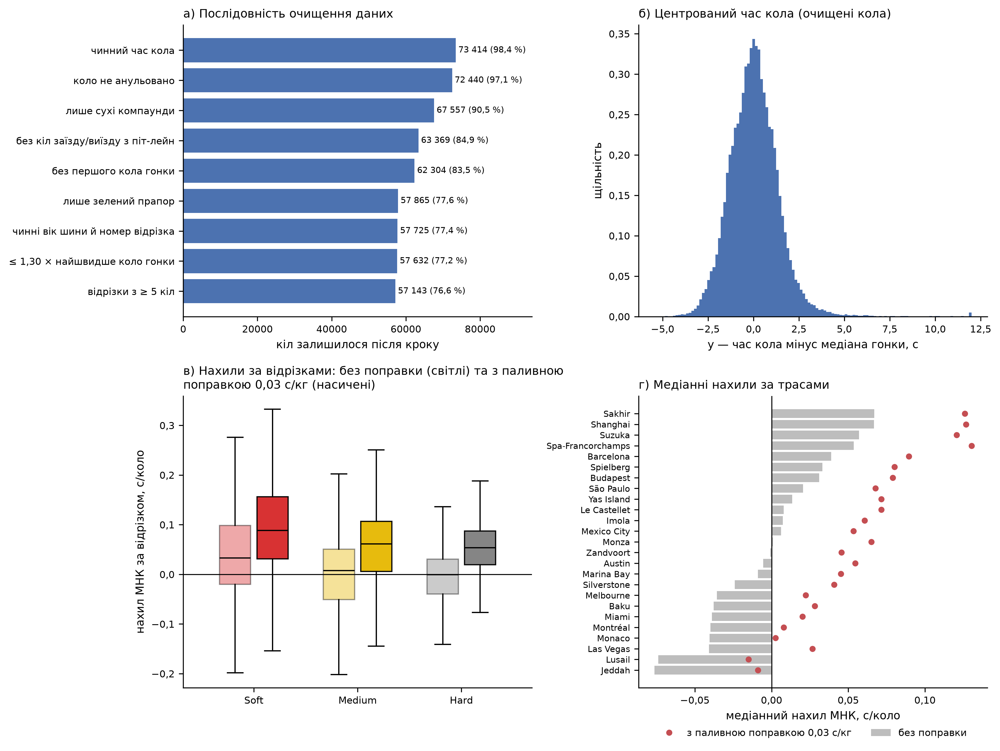

**fig02_prior_ppc_primary.** Апріорна та апостеріорна предиктивні перевірки моделі «primary». (а, б) спільні наслідки апріорних розподілів; (в–д) репліки спостережень за оцінених латентних траєкторій, усічені тим самим правилом, що й дані; (е) репліки нових відрізків (нові ефекти відрізків і латентні траєкторії з апостеріорних гіперпараметрів) проти емпіричних квантилів нахилів МНК. Вибіркову скошеність не використано як критерій: за індексу хвоста, близького до 2, вона не має скінченної дисперсії. [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

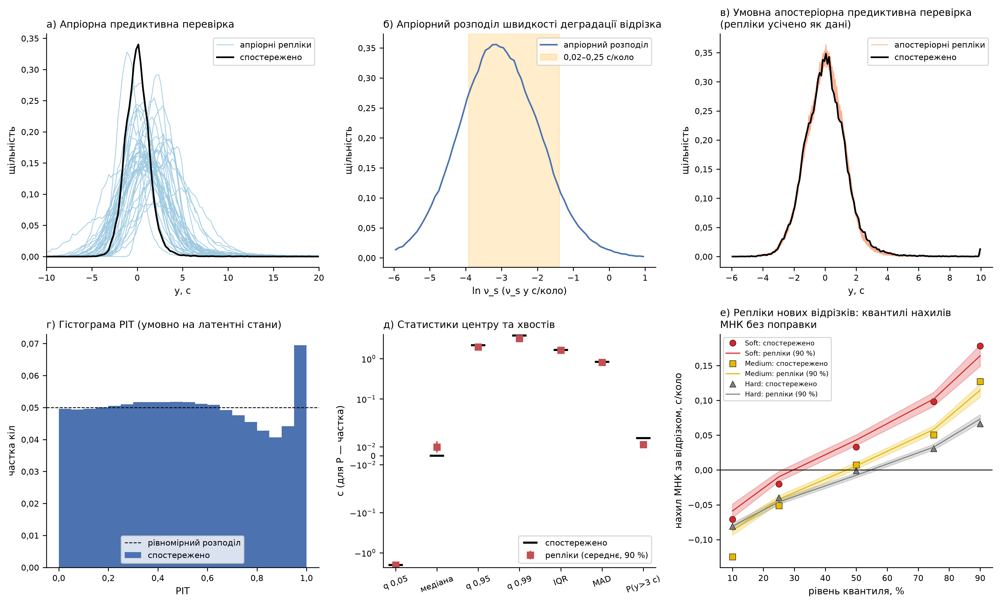

**fig03_compounds_primary.** Ефекти компаундів моделі «primary»: (а) швидкість деградації на середньому рівні інших чинників; (б) множники exp(C_c) відносно загального рівня з кількістю відрізків; (в) попарні різниці швидкостей зі спільних апостеріорних реалізацій та ймовірність порядку. [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

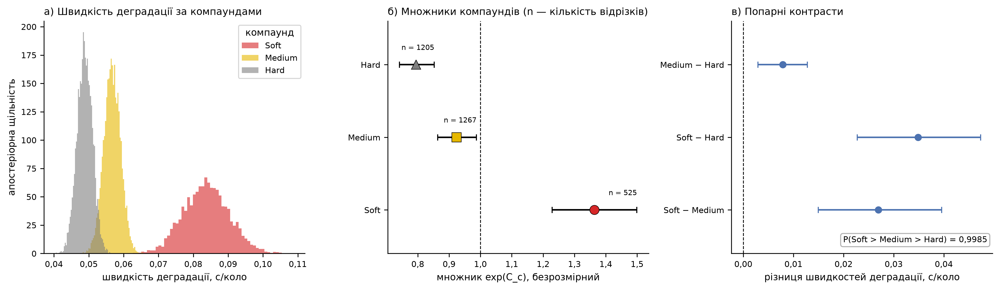

**fig04_tracks_primary.** Трасові ефекти моделі «primary»: (а) швидкість деградації на трасі за середнього рівня інших чинників; (б) та сама швидкість у відсотках медіанного часу кола траси (нормування зменшує, але не усуває залежність від довжини кола); (в) паливно-трасовий коефіцієнт γ_q, який відокремлюється від ν лише за припущень підрозд. 5.4. [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

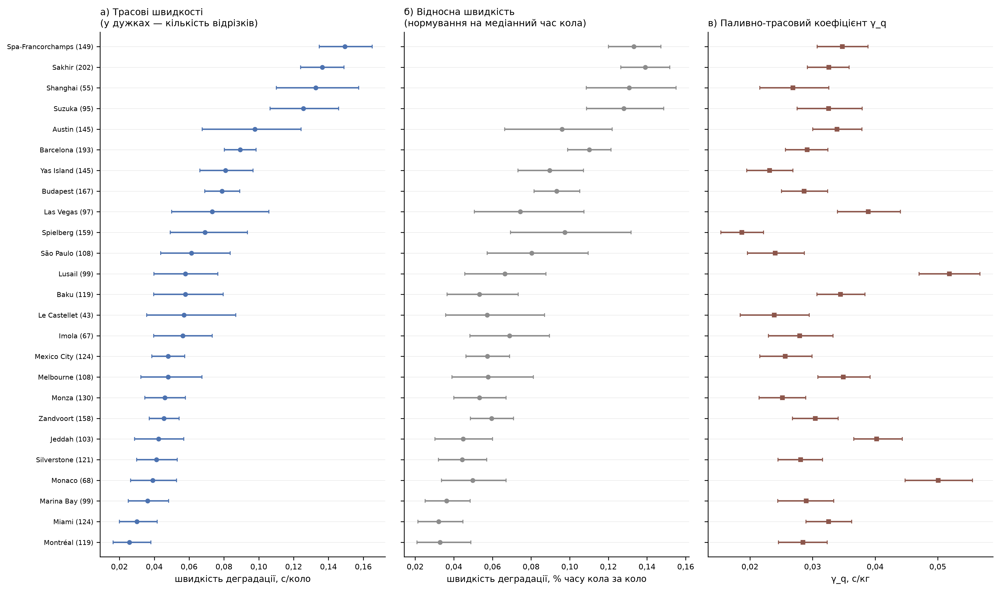

**fig05_scales_primary.** Джерела неоднорідності швидкості деградації, модель «primary»: (а) гіперпараметри σ та реалізовані стандартні відхилення оцінених ефектів для кожного компонента (для компаунда гіперпараметра немає — апріорна шкала фіксована); (б) частки дисперсії лінійного предиктора швидкості між відрізками з урахуванням фактичної кількості відрізків у групах; окремий стовпчик — сума коваріацій перехресних ефектів. [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

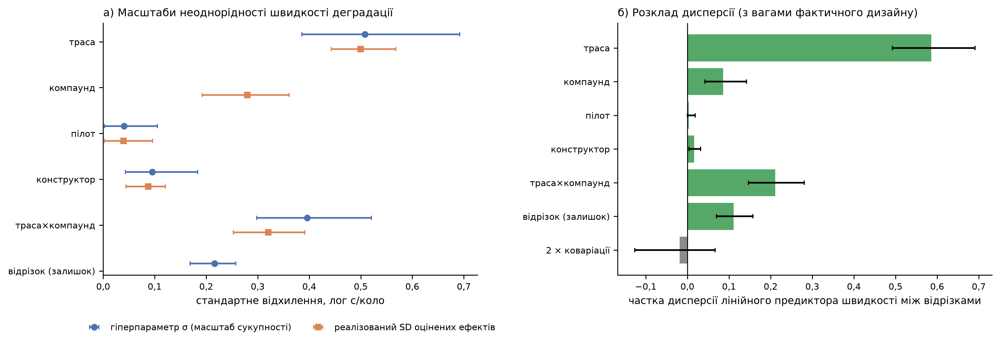

**fig06_interaction_primary.** Взаємодія «траса — компаунд», модель «primary»: (а) медіана ефекту взаємодії, кількість відрізків у комірці та половина ширини 94 % ETI у логарифмічній шкалі; кольорова шкала охоплює весь діапазон значень; комірки з n < 5 набрано курсивом (оцінка визначається переважно апріорним розподілом); (б) повна швидкість деградації з урахуванням загального рівня, ефектів компаунда й траси та взаємодії. [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

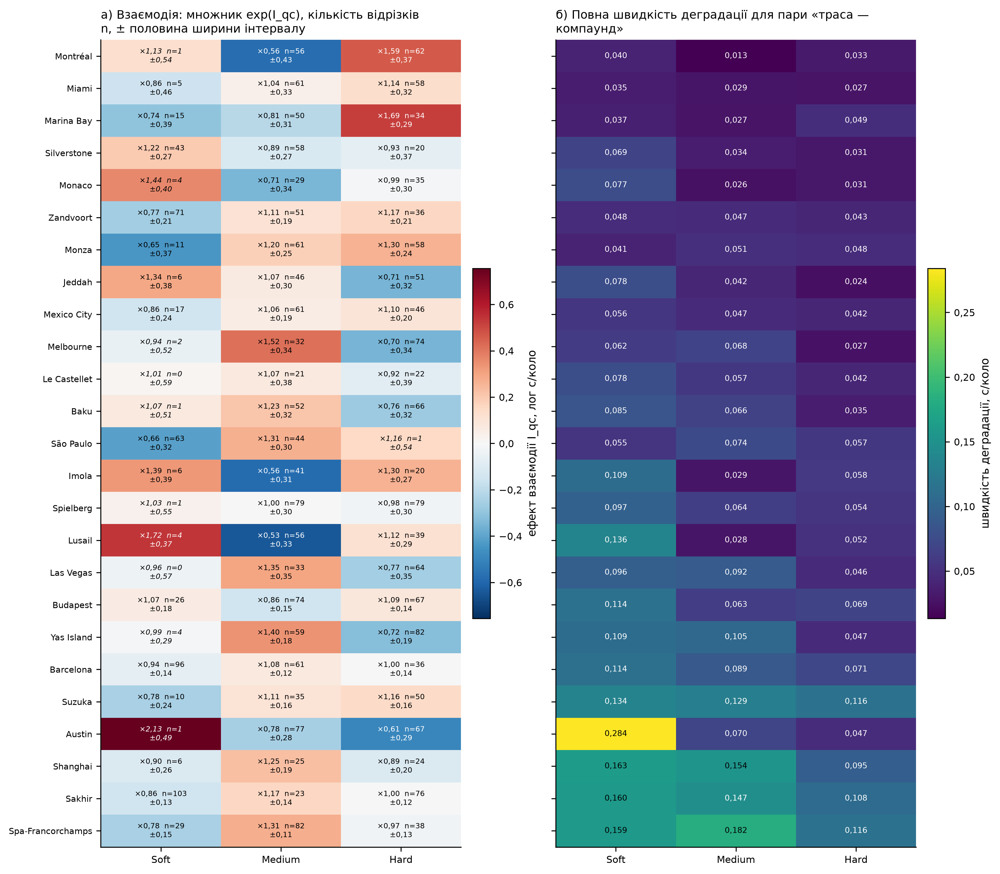

**fig07_groups_primary.** Ефекти конструкторів і пілотів, модель «primary», із 94 % ETI та кількістю відрізків. Порівняння масштабів σ_G і σ_D подано апостеріорною різницею, а не перекриттям окремих інтервалів. Ефекти описують гоночний темп і можуть бути змішані зі стратегією та трафіком. [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

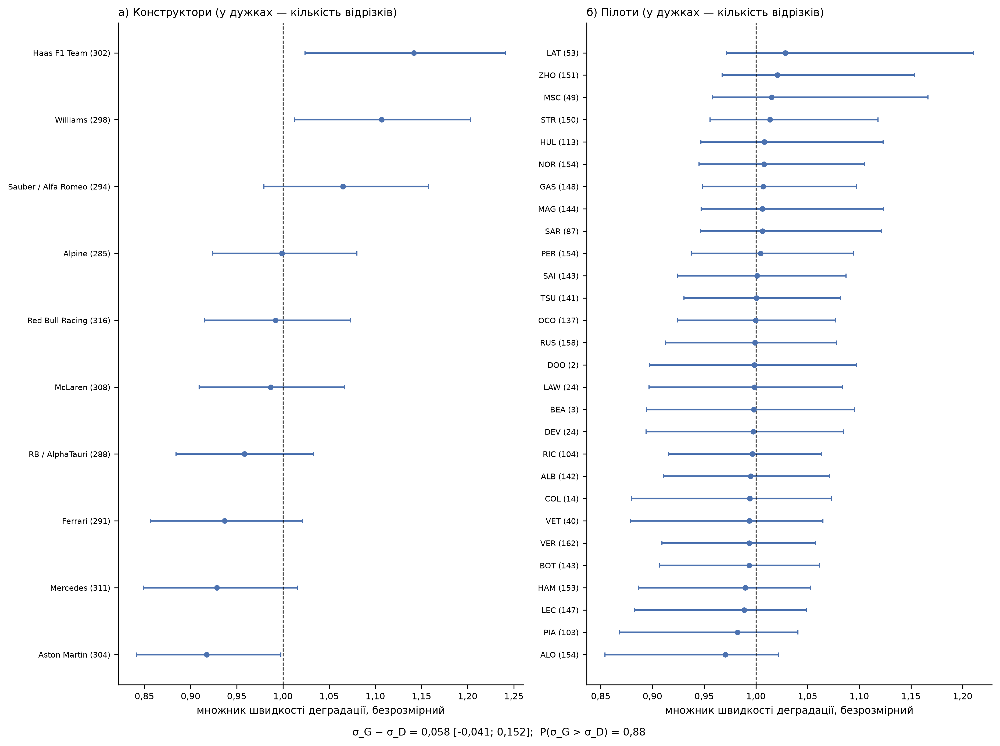

**fig08_examples_smoothing_primary.** Приклади відрізків (згладжування: використано всі кола відрізка): дані, інтервал латентної траєкторії з паливним членом і предиктивний інтервал; правило вибору відрізків наведено в заголовках. Модель «primary». [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

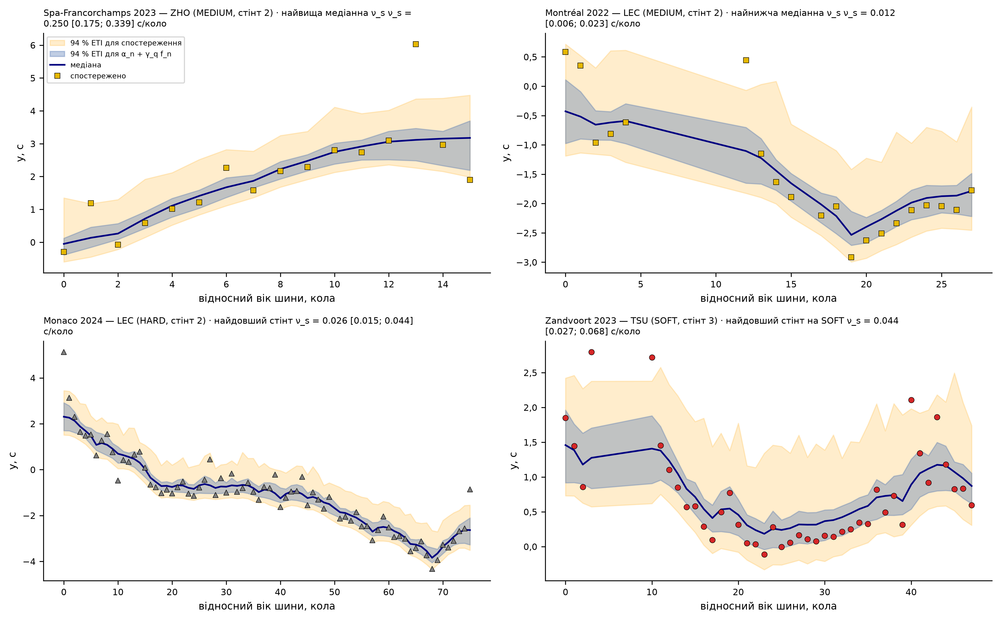

**figS3_recovery_rec_baseline_0_est.** Додаток: відновлення параметрів на синтетичних даних (rec_baseline_0_est); генератор даних не має спільного коду з моделлю. Одна репліка — приклад; зведення за репліками подано в таблиці відновлення. [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

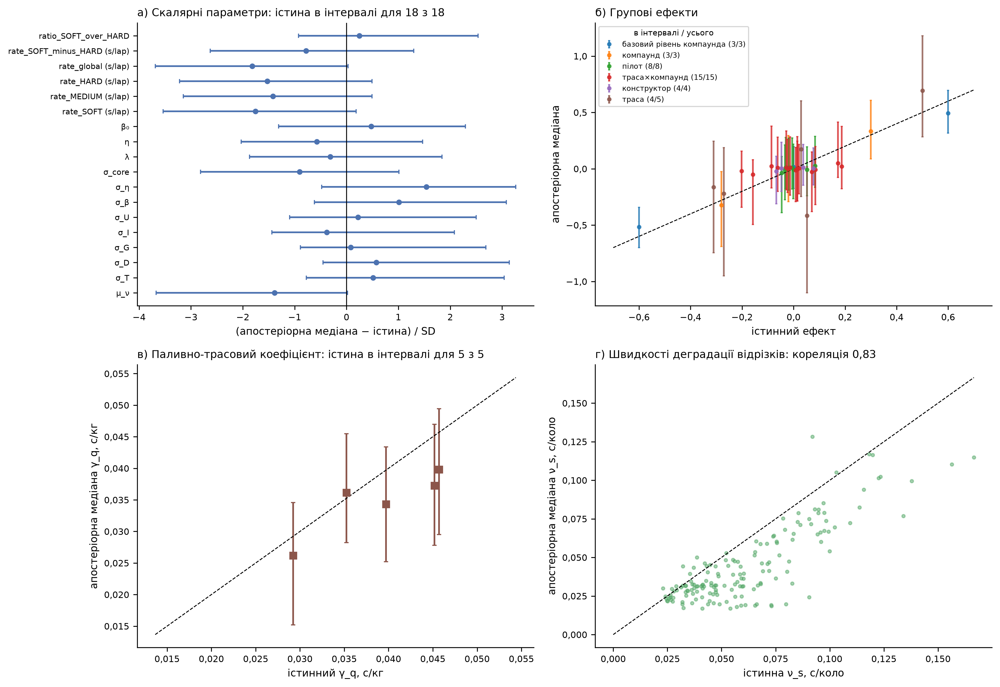

**figS4_sensitivity_all.** Чутливість основних оцінок до специфікації моделі (кожен рядок — окреме оцінювання; діагностичний стан — у таблиці порівняння моделей). [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

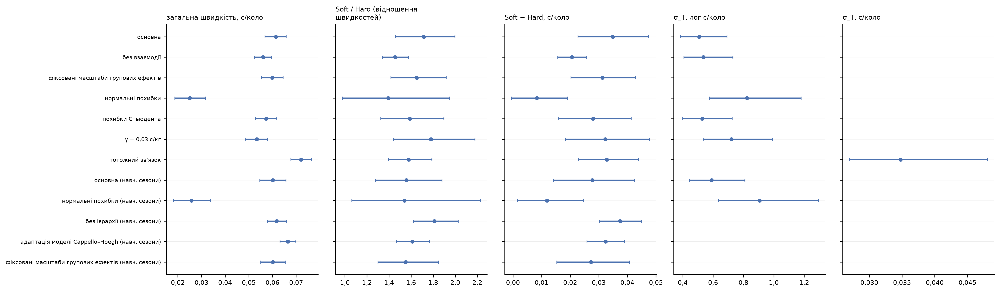

**figS5_forecast.** Прогнозна перевірка: навчання на попередніх сезонах, прогноз останніх кіл відрізків тестового сезону лише з їхнього початку (фіксований початок прогнозу). Середні за гонками з 94 % довірчим інтервалом (t-розподіл; одиниця вибірки — гонка); покриття предиктивних інтервалів проти номіналу (пунктир). [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

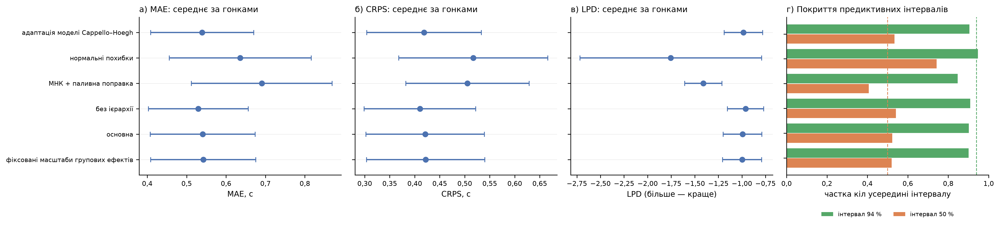

**fig08_examples_forecasting_forecast.** Приклади прогнозу: параметри відрізка оцінено лише за колами ліворуч від пунктиру, праворуч — прогноз із предиктивним інтервалом. Модель «forecast». [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

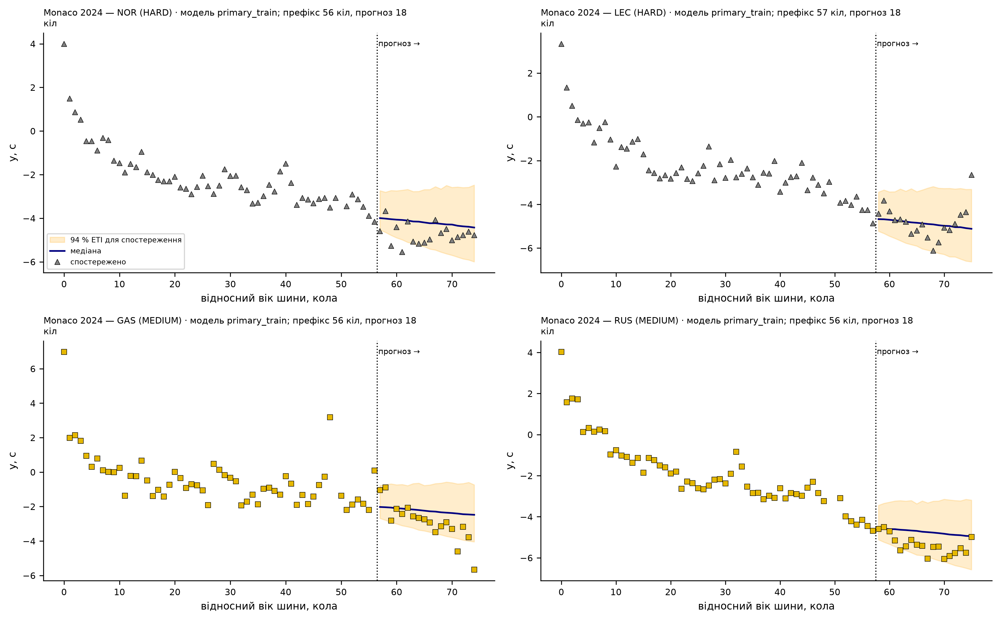

**figS1_trace_rank_primary.** Додаток: траєкторії ланцюгів і рангові гістограми гіперпараметрів моделі «primary». [запуск FULL-2483ee9f; інтервали — 94% ETI, якщо не зазначено інше]

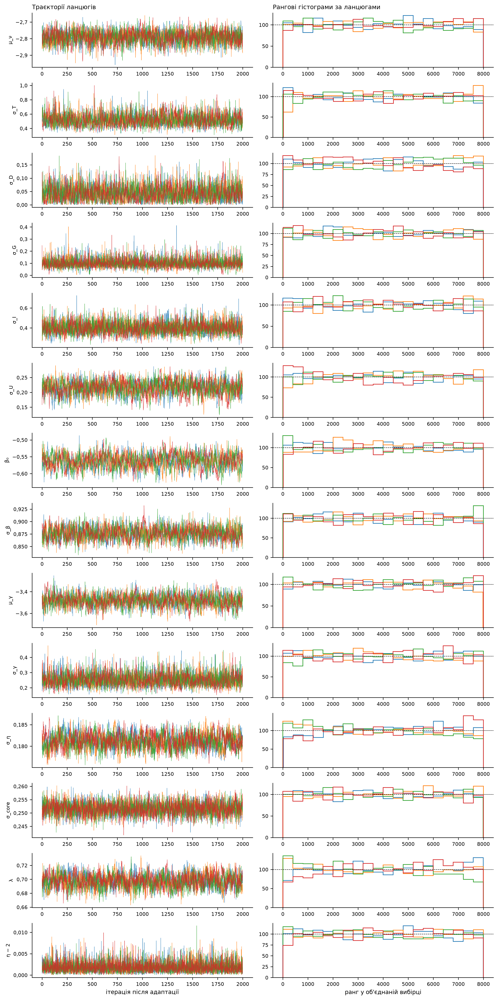

In [12]:
figdir = cfg.out_dir / "figures"; caps = json.load(open(figdir / "captions_uk.json", encoding="utf-8"))
for key in ("data", "ppc", "compound", "tracks", "scales", "interaction", "groups", "examples", "recovery", "sensitivity", "forecast", "forecast_examples", "diagnostics"):
    p = ex.get("figures", {}).get(key)
    if p and Path(p).exists():
        name = Path(p).stem
        display(Markdown(f"**{name}.** {caps.get(name, '')}")); display(Image(filename=p, width=1000))


## 8. Таблиці для статті та звіт для редакції


In [13]:
tdir = cfg.out_dir / "tables"
for name in ("compound", "compound_contrasts", "order", "scales", "sigma_cmp", "residual", "identification", "gates", "model_comparison", "sensitivity", "forecast", "forecast_pairs", "recovery"):
    p = ex.get("tables", {}).get(name)
    if p and Path(p).exists():
        display(Markdown(f"**{Path(p).stem}**")); display(pd.read_csv(p).head(40))


**compound_primary**

,compound,n_stints,n_laps,multiplier_median,multiplier_lo,multiplier_hi,rate_median_s_per_lap,rate_lo,rate_hi,rate_mean,rate_sd,effect_median,effect_lo,effect_hi,effect_scale,P(rate>0)
0,SOFT,525,7130,1.3631,1.2287,1.4993,0.0837,0.0719,0.0962,0.0838,0.0065,0.3098,0.2060,0.4050,лог с/коло,1.0
1,MEDIUM,1267,21433,0.9238,0.8638,0.9874,0.0567,0.0522,0.0612,0.0567,0.0024,-0.0793,-0.1464,-0.0126,лог с/коло,1.0
2,HARD,1205,28580,0.7950,0.7419,0.8525,0.0488,0.0447,0.0529,0.0488,0.0022,-0.2294,-0.2985,-0.1596,лог с/коло,1.0


**compound_contrasts_primary**

,contrast,rate_diff_median_s_per_lap,rate_diff_lo,rate_diff_hi,ratio_median,ratio_lo,ratio_hi,P(diff>0),P_mcse_or_bound,ess_indicator
0,SOFT − MEDIUM,0.0269,0.0150,0.0396,1.4756,1.2578,1.7170,1.0000,0.0004,8000.0000
1,SOFT − HARD,0.0349,0.0227,0.0474,1.7147,1.4579,1.9967,1.0000,0.0004,8000.0000
2,MEDIUM − HARD,0.0078,0.0029,0.0128,1.1608,1.0572,1.2747,0.9985,0.0005,6019.2754


**order_probabilities_primary**

,scope,event,probability,mcse_or_rule_of_three_bound,ess_indicator,n_draws,P(SOFT>HARD),n_stints_S/M/H,min_cell_n
0,global (geometric-mean track),SOFT > MEDIUM > HARD,0.9985,0.0005,6019.2754,8000,NaN,NaN,NaN
1,global (geometric-mean track),SOFT > HARD,1.0000,0.0004,8000.0000,8000,NaN,NaN,NaN
2,global (geometric-mean track),SOFT > MEDIUM,1.0000,0.0004,8000.0000,8000,NaN,NaN,NaN
3,global (geometric-mean track),MEDIUM > HARD,0.9985,0.0005,6019.2754,8000,NaN,NaN,NaN
4,track Austin,SOFT > MEDIUM > HARD (full rate),0.9921,0.0013,4594.7570,8000,0.9995,1/77/67,1.0
5,track Baku,SOFT > MEDIUM > HARD (full rate),0.7064,0.0059,5925.1651,8000,0.9702,1/52/66,1.0
6,track Barcelona,SOFT > MEDIUM > HARD (full rate),0.9761,0.0021,5501.9696,8000,1.0000,96/61/36,36.0
7,track Budapest,SOFT > MEDIUM > HARD (full rate),0.2130,0.0053,6040.1294,8000,0.9999,26/74/67,26.0
8,track Imola,SOFT > MEDIUM > HARD (full rate),0.0005,0.0002,8021.7973,8000,0.9541,6/41/20,6.0
9,track Jeddah,SOFT > MEDIUM > HARD (full rate),0.9469,0.0032,4978.9924,8000,0.9988,6/46/51,6.0


... (14 outputs left out)

**forecast_summary**

,model,scheme,n_laps,n_races,MAE,RMSE_pooled,CRPS,coverage94,width94,coverage50,width50,MAE_race_mean,MAE_race_se,CRPS_race_mean,CRPS_race_se,LPD,LPD_race_mean,LPD_race_se,n_lpd_nonfinite
0,ch_adapted_train,fixed_origin,4785,23,0.5263,0.9743,0.4070,0.9047,2.2481,0.5342,0.6744,0.5395,0.0659,0.4185,0.0578,-0.9610,-0.9845,0.1029,0
1,ch_adapted_train,rolling_one_step,4785,23,0.4330,0.9023,0.3425,0.9103,1.9121,0.5415,0.5094,0.4471,0.0649,0.3546,0.0584,-0.7203,-0.7468,0.1056,0
2,gauss_train,fixed_origin,4785,23,0.6244,1.0493,0.5068,0.9467,4.0210,0.7429,1.4418,0.6361,0.0909,0.5172,0.0752,-1.6410,-1.7540,0.4860,0
3,gauss_train,rolling_one_step,4785,23,0.4618,0.8693,0.3821,0.9248,2.6034,0.7294,0.9347,0.4730,0.0657,0.3911,0.0573,-1.7236,-1.9046,0.7866,0
4,ols_fuel_ext,fixed_origin,4785,23,0.6542,1.0260,0.4827,0.8468,2.4534,0.4071,0.8325,0.6907,0.0900,0.5055,0.0622,-1.3766,-1.4092,0.0992,0
5,pooled_train,fixed_origin,4785,23,0.5160,0.9622,0.3986,0.9089,2.2557,0.5409,0.6751,0.5295,0.0639,0.4105,0.0563,-0.9390,-0.9611,0.0968,0
6,pooled_train,rolling_one_step,4785,23,0.4318,0.9008,0.3415,0.9114,1.9173,0.5440,0.5082,0.4460,0.0646,0.3535,0.0581,-0.7166,-0.7403,0.1043,0
7,primary_train,fixed_origin,4785,23,0.5234,0.9767,0.4059,0.9020,2.2259,0.5227,0.6584,0.5407,0.0671,0.4209,0.0597,-0.9611,-0.9930,0.1033,0
8,primary_train,rolling_one_step,4785,23,0.4375,0.9074,0.3451,0.9095,1.9146,0.5279,0.5044,0.4527,0.0662,0.3581,0.0594,-0.7273,-0.7555,0.1062,0
9,unpooled_train,fixed_origin,4785,23,0.5254,0.9782,0.4073,0.9007,2.2223,0.5202,0.6578,0.5421,0.0672,0.4218,0.0597,-0.9663,-0.9976,0.1045,0


**forecast_paired_differences**

,model_a,model_b,metric,n_races,mean_diff_a_minus_b,se_race,ci94_lo,ci94_hi,t_quantile,ci_method,share_races_a_better,higher_is_better
0,ch_adapted_train,gauss_train,mae,23,-0.0966,0.0306,-0.1573,-0.0360,1.9829,"t(22), 94%",0.9565,False
1,ch_adapted_train,gauss_train,crps,23,-0.0987,0.0231,-0.1445,-0.0529,1.9829,"t(22), 94%",0.9130,False
2,ch_adapted_train,gauss_train,lpd,23,0.7695,0.4198,-0.0630,1.6020,1.9829,"t(22), 94%",0.8696,True
3,ch_adapted_train,ols_fuel_ext,mae,23,-0.1512,0.0363,-0.2231,-0.0793,1.9829,"t(22), 94%",0.9130,False
4,ch_adapted_train,ols_fuel_ext,crps,23,-0.0869,0.0178,-0.1222,-0.0517,1.9829,"t(22), 94%",0.8696,False
5,ch_adapted_train,ols_fuel_ext,lpd,23,0.4247,0.0640,0.2978,0.5516,1.9829,"t(22), 94%",0.9130,True
6,ch_adapted_train,pooled_train,mae,23,0.0100,0.0063,-0.0025,0.0225,1.9829,"t(22), 94%",0.4783,False
7,ch_adapted_train,pooled_train,crps,23,0.0081,0.0046,-0.0011,0.0172,1.9829,"t(22), 94%",0.4348,False
8,ch_adapted_train,pooled_train,lpd,23,-0.0233,0.0128,-0.0487,0.0021,1.9829,"t(22), 94%",0.3913,True
9,ch_adapted_train,primary_train,mae,23,-0.0013,0.0098,-0.0207,0.0181,1.9829,"t(22), 94%",0.6957,False


> **[v1.1]** Вихід наступної комірки сформовано кодом v1.0 у запуску `FULL-2483ee9f`: матриця відповіді там має старі коди (`R2.x`) і старі статуси. Чинна матриця — `docs/REVIEWER_RESPONSE_uk.md`; після `REPORT_ONLY` комірка покаже її оновлену версію з фактичним станом кожного експерименту.

In [14]:
# [v1.1] код комірки змінено після запуску FULL-2483ee9f; збережений вихід отримано кодом v1.0 (той самий run ID)
rdir = cfg.out_dir / "reports"
display(Markdown((rdir / "results_summary_uk.md").read_text(encoding="utf-8")) if (rdir / "results_summary_uk.md").exists() else "no summary (primary fit missing)")
if (rdir / "old_conclusions_status.csv").exists():
    display(Markdown("**Статус старих висновків:**")); display(pd.read_csv(rdir / "old_conclusions_status.csv"))
display(Markdown("**Матриця відповіді рецензенту (`reports/reviewer_response_matrix.csv`):**")); display(pd.read_csv(rdir / "reviewer_response_matrix.csv"))
display(Markdown("**Статус експериментів (`reports/experiments_status.csv`):**")); display(pd.read_csv(rdir / "experiments_status.csv")[["experiment", "пріоритет", "in_queue", "статус", "worst_rhat", "min_ess", "ebfmi_min", "sampling_hours", "fit_id"]])
display(Markdown((rdir / "editorial_checklist.md").read_text(encoding="utf-8")))


## Результати (автоматично згенеровано з run FULL-2483ee9f, режим FULL)

Після очищення: 57,143 кіл, 2,997 відрізків, 66 гонок, 25 трас, 28 пілотів, 10 конструкторів; 54,146 латентних інновацій.

**Діагностика MCMC (primary):** 4 ланцюги × 2000 ітерацій після адаптації; найгірший R̂ = 1.0083, мін. ESS bulk/tail = 588/796, макс. MCSE/SD = 0.042, дивергенцій 0, E-BFMI min 0.268. Не пройдено: E-BFMI min 0.268 < 0.3.

**Загальний рівень швидкості деградації** = 0.061 [0.057; 0.066] с/коло (94% ETI; функція зв'язку: log).

**Компаунди:** SOFT: ×1.36 [1.23; 1.50], швидкість 0.084 [0.072; 0.096] с/коло, n = 525; MEDIUM: ×0.92 [0.86; 0.99], швидкість 0.057 [0.052; 0.061] с/коло, n = 1267; HARD: ×0.79 [0.74; 0.85], швидкість 0.049 [0.045; 0.053] с/коло, n = 1205.

**Контрасти (зі спільних апостеріорних реалізацій):** SOFT − MEDIUM: Δ = 0.027 [0.015; 0.040] с/коло, відношення 1.48 [1.26; 1.72], P(Δ>0) = 1.000 ± 0.000; SOFT − HARD: Δ = 0.035 [0.023; 0.047] с/коло, відношення 1.71 [1.46; 2.00], P(Δ>0) = 1.000 ± 0.000; MEDIUM − HARD: Δ = 0.008 [0.003; 0.013] с/коло, відношення 1.16 [1.06; 1.27], P(Δ>0) = 0.999 ± 0.000.

**Ймовірності порядку (загальний рівень):** P(SOFT > MEDIUM > HARD) = 0.9985 (MCSE або межа 3/ESS: 0.0005); P(SOFT > HARD) = 1.0000 (MCSE або межа 3/ESS: 0.0004); P(SOFT > MEDIUM) = 1.0000 (MCSE або межа 3/ESS: 0.0004); P(MEDIUM > HARD) = 0.9985 (MCSE або межа 3/ESS: 0.0005).

За трасами (повні швидкості з взаємодією): P(SOFT>MEDIUM>HARD) ≥ 0.9 на 3 з 25 трас; нижче 0.9: Baku (0.71; n = 1/52/66), Budapest (0.21; n = 26/74/67), Imola (0.00; n = 6/41/20), Las Vegas (0.55; n = 0/33/64), Le Castellet (0.64; n = 0/21/22), Lusail (0.01; n = 4/56/39), Marina Bay (0.00; n = 15/50/34), Melbourne (0.42; n = 2/32/74), Mexico City (0.61; n = 17/61/46), Miami (0.36; n = 5/61/58), Monaco (0.23; n = 4/29/35), Montréal (0.00; n = 1/56/62), Monza (0.10; n = 11/61/58), Sakhir (0.78; n = 103/23/76), Shanghai (0.60; n = 6/25/24), Silverstone (0.63; n = 43/58/20), Spa-Francorchamps (0.09; n = 29/82/38), Spielberg (0.74; n = 1/79/79), Suzuka (0.47; n = 10/35/50), São Paulo (0.01; n = 63/44/1), Yas Island (0.57; n = 4/59/82), Zandvoort (0.32; n = 71/51/36).

**Масштаби неоднорідності (гіперпараметри σ):** траса: 0.508 [0.385; 0.692] лог с/коло; пілот: 0.041 [0.003; 0.105] лог с/коло; конструктор: 0.095 [0.043; 0.183] лог с/коло; траса×компаунд: 0.396 [0.298; 0.521] лог с/коло; відрізок (залишок): 0.216 [0.169; 0.258] лог с/коло.

**Частки дисперсії лінійного предиктора швидкості між відрізками:** компаунд: 0.086 [0.042; 0.142]; траса: 0.586 [0.493; 0.691]; пілот: 0.003 [0.000; 0.019]; конструктор: 0.016 [0.004; 0.032]; траса×компаунд: 0.211 [0.146; 0.281]; відрізок (залишок): 0.111 [0.070; 0.157]; 2×коваріації (перехресний дизайн): -0.019 [-0.126; 0.067].

**Конструктори та пілоти:** σ_G − σ_D (log-rate) = 0.058 [-0.041; 0.152], P(σ_G > σ_D) = 0.88.

**Похибки спостережень, процесний шум, базові рівні:** σ_core = 0.2516 [0.2470; 0.2563]; λ = 0.6978 [0.6791; 0.7163]; η = 2.0015 [2.0002; 2.0049]; σ_η = 0.1812 [0.1779; 0.1845]; σ_β = 0.8763 [0.8527; 0.9006]; β₀ = -0.5616 [-0.6040; -0.5244].

**Розділення ν і γ:** corr(μ_ν, μ_γ) = 0.20; SD(μ_γ) апостеріорне/апріорне = 0.14; середня за трасами кореляція трасової швидкості та γ_q = 0.51.

**Знак швидкості:** у цій специфікації (log-зв'язок) ν_s > 0 за побудовою на всіх рівнях; це припущення моделі, а не емпіричний висновок. Емпірична перевірка — експеримент `signed_full` (тотожна функція зв'язку).

**Умовна апостеріорна предиктивна перевірка (репліки усічено тим самим правилом, що й дані):** iqr: спостережено 1.667, репліки 1.628 (p = 0.00); mad: спостережено 0.833, репліки 0.814 (p = 0.00); p_gt_3: спостережено 0.020, репліки 0.013 (p = 0.00); q05: спостережено -2.013, репліки -2.006 (p = 0.28); q50: спостережено 0.000, репліки 0.010 (p = 0.01); q95: спостережено 2.166, репліки 1.975 (p = 0.00); q99: спостережено 3.788, репліки 3.195 (p = 0.00); skew_raw_unreliable: спостережено 1.701, репліки 0.944 (p = 0.00).

**PIT:** частка спостережень у верхніх 5 % / 1 % умовного предиктивного розподілу: 0.069 / 0.015 (номінал 0.05 / 0.01); у нижніх: 0.050 / 0.011.

**PSIS-LOO (умовно на латентні стани):** elpd = -27893.9 (SE 314.8), p_loo = 25413.7; частка кіл з k̂ > 0.7: 0.256 — оцінка НЕНАДІЙНА, використовувати лише разом із прогнозною перевіркою.

**Прогноз (фіксований початок; остання чверть відрізків тестового сезону лише з префікса):** ch_adapted_train: MAE 0.526, RMSE 0.974, CRPS 0.407, LPD -0.961, покриття94 0.905; gauss_train: MAE 0.624, RMSE 1.049, CRPS 0.507, LPD -1.641, покриття94 0.947; ols_fuel_ext: MAE 0.654, RMSE 1.026, CRPS 0.483, LPD -1.377, покриття94 0.847; pooled_train: MAE 0.516, RMSE 0.962, CRPS 0.399, LPD -0.939, покриття94 0.909; primary_train: MAE 0.523, RMSE 0.977, CRPS 0.406, LPD -0.961, покриття94 0.902; unpooled_train: MAE 0.525, RMSE 0.978, CRPS 0.407, LPD -0.966, покриття94 0.901.

**Парні різниці за гонками (a − b; інтервал за t-розподілом):** ch_adapted_train − gauss_train [mae]: -0.0966 (SE 0.0306; [-0.1573; -0.0360]); ch_adapted_train − gauss_train [crps]: -0.0987 (SE 0.0231; [-0.1445; -0.0529]); ch_adapted_train − gauss_train [lpd]: +0.7695 (SE 0.4198; [-0.0630; +1.6020]); ch_adapted_train − ols_fuel_ext [mae]: -0.1512 (SE 0.0363; [-0.2231; -0.0793]); ch_adapted_train − ols_fuel_ext [crps]: -0.0869 (SE 0.0178; [-0.1222; -0.0517]); ch_adapted_train − ols_fuel_ext [lpd]: +0.4247 (SE 0.0640; [+0.2978; +0.5516]); ch_adapted_train − pooled_train [mae]: +0.0100 (SE 0.0063; [-0.0025; +0.0225]); ch_adapted_train − pooled_train [crps]: +0.0081 (SE 0.0046; [-0.0011; +0.0172]); ch_adapted_train − pooled_train [lpd]: -0.0233 (SE 0.0128; [-0.0487; +0.0021]); ch_adapted_train − primary_train [mae]: -0.0013 (SE 0.0098; [-0.0207; +0.0181]); ch_adapted_train − primary_train [crps]: -0.0024 (SE 0.0073; [-0.0168; +0.0120]); ch_adapted_train − primary_train [lpd]: +0.0085 (SE 0.0207; [-0.0325; +0.0496]); ch_adapted_train − unpooled_train [mae]: -0.0027 (SE 0.0090; [-0.0206; +0.0152]); ch_adapted_train − unpooled_train [crps]: -0.0033 (SE 0.0068; [-0.0168; +0.0101]); ch_adapted_train − unpooled_train [lpd]: +0.0131 (SE 0.0215; [-0.0295; +0.0558]); gauss_train − ols_fuel_ext [mae]: -0.0546 (SE 0.0338; [-0.1217; +0.0125]); gauss_train − ols_fuel_ext [crps]: +0.0117 (SE 0.0258; [-0.0395; +0.0629]); gauss_train − ols_fuel_ext [lpd]: -0.3448 (SE 0.4265; [-1.1904; +0.5008]); gauss_train − pooled_train [mae]: +0.1066 (SE 0.0319; [+0.0434; +0.1698]); gauss_train − pooled_train [crps]: +0.1067 (SE 0.0235; [+0.0601; +0.1534]); gauss_train − pooled_train [lpd]: -0.7928 (SE 0.4201; [-1.6257; +0.0401]); gauss_train − primary_train [mae]: +0.0954 (SE 0.0297; [+0.0365; +0.1542]); gauss_train − primary_train [crps]: +0.0963 (SE 0.0215; [+0.0537; +0.1389]); gauss_train − primary_train [lpd]: -0.7610 (SE 0.4161; [-1.5860; +0.0640]); gauss_train − unpooled_train [mae]: +0.0940 (SE 0.0294; [+0.0357; +0.1523]); gauss_train − unpooled_train [crps]: +0.0954 (SE 0.0215; [+0.0527; +0.1380]); gauss_train − unpooled_train [lpd]: -0.7564 (SE 0.4167; [-1.5826; +0.0698]); ols_fuel_ext − pooled_train [mae]: +0.1612 (SE 0.0349; [+0.0920; +0.2304]); ols_fuel_ext − pooled_train [crps]: +0.0950 (SE 0.0158; [+0.0637; +0.1263]); ols_fuel_ext − pooled_train [lpd]: -0.4480 (SE 0.0548; [-0.5567; -0.3393]); ols_fuel_ext − primary_train [mae]: +0.1499 (SE 0.0333; [+0.0839; +0.2160]); ols_fuel_ext − primary_train [crps]: +0.0845 (SE 0.0157; [+0.0534; +0.1157]); ols_fuel_ext − primary_train [lpd]: -0.4162 (SE 0.0606; [-0.5363; -0.2961]); ols_fuel_ext − unpooled_train [mae]: +0.1485 (SE 0.0339; [+0.0812; +0.2158]); ols_fuel_ext − unpooled_train [crps]: +0.0836 (SE 0.0163; [+0.0514; +0.1159]); ols_fuel_ext − unpooled_train [lpd]: -0.4116 (SE 0.0628; [-0.5362; -0.2870]); pooled_train − primary_train [mae]: -0.0112 (SE 0.0069; [-0.0250; +0.0025]); pooled_train − primary_train [crps]: -0.0104 (SE 0.0057; [-0.0218; +0.0009]); pooled_train − primary_train [lpd]: +0.0318 (SE 0.0193; [-0.0065; +0.0702]); pooled_train − unpooled_train [mae]: -0.0127 (SE 0.0068; [-0.0262; +0.0009]); pooled_train − unpooled_train [crps]: -0.0114 (SE 0.0056; [-0.0225; -0.0002]); pooled_train − unpooled_train [lpd]: +0.0364 (SE 0.0215; [-0.0062; +0.0791]); primary_train − unpooled_train [mae]: -0.0014 (SE 0.0013; [-0.0040; +0.0012]); primary_train − unpooled_train [crps]: -0.0009 (SE 0.0010; [-0.0029; +0.0010]); primary_train − unpooled_train [lpd]: +0.0046 (SE 0.0042; [-0.0037; +0.0128]).

**Чи допомагає прогнозу адаптивне ієрархічне об'єднання (основна схема, усі відрізки; MAE і CRPS — втрати, LPD — більше краще):** навчені масштаби − фіксовані масштаби (primary_train − unpooled_train): MAE -0.0014 [-0.0040; +0.0012] — інтервал містить нуль: різницю не підтверджено; CRPS -0.0009 [-0.0029; +0.0010] — інтервал містить нуль: різницю не підтверджено; LPD +0.0046 [-0.0037; +0.0128] — інтервал містить нуль: різницю не підтверджено. групові ефекти з фіксованими масштабами − без групових ефектів (unpooled_train − pooled_train): MAE +0.0127 [-0.0009; +0.0262] — інтервал містить нуль: різницю не підтверджено; CRPS +0.0114 [+0.0002; +0.0225] — інтервал не містить нуля: краща друга модель пари; LPD -0.0364 [-0.0791; +0.0062] — інтервал містить нуль: різницю не підтверджено. навчені масштаби − без групових ефектів (primary_train − pooled_train): MAE +0.0112 [-0.0025; +0.0250] — інтервал містить нуль: різницю не підтверджено; CRPS +0.0104 [-0.0009; +0.0218] — інтервал містить нуль: різницю не підтверджено; LPD -0.0318 [-0.0702; +0.0065] — інтервал містить нуль: різницю не підтверджено. Інтервал, що містить нуль, означає лише, що різницю не підтверджено на цих гонках, а не що моделі рівноцінні. Інші схеми — forecast/forecast_hierarchy_ablation.csv.

**Статус старих висновків:**

,старий висновок,статус,коментар
0,"Модель «верифіковано», вона «успішно ізолює чи...",змінено,«верифіковано» замінено переліком виконаних пе...
1,"«Повна збіжність» ланцюгів (R̂=1.09, ESS=43 дл...",змінено,"найгірший R̂ 1.0083, мін. ESS 588; не пройдено..."
2,Геометрична середня швидкість ≈ 0.067 с/коло [...,змінено,нове значення 0.061 [0.057; 0.066] с/коло (інш...
3,Множники Soft/Medium/Hard ≈ 1.31/0.94/0.82; So...,підтверджено,відношення медіан швидкостей SOFT/HARD = 1.71;...
4,Порядок Soft > Medium > Hard з «дуже високою й...,підтверджено (на загальному рівні),P = 0.9985 (MCSE/межа 0.0005); за трасами P ≥ ...
5,«Статистична значущість та незворотність» дегр...,змінено,додатність ν — припущення log-параметризації; ...
6,Найбільше джерело варіації — траса (σ_T ≈ 0.444),підтверджено,σ_T = 0.508 [0.385; 0.692]; частка дисперсії 0...
7,«Суттєва значущість» взаємодії траса–компаунд,послаблено,σ_I = 0.396 [0.298; 0.521]; «значущість» замін...
8,Конструктори «значно стабільніші» за пілотів (...,не підтверджено,"σ_G − σ_D = 0.058 [-0.041; 0.152], P(σ_G > σ_D..."
9,Переоцінена правостороння скошеність — «очікув...,змінено,"перевірку переформульовано: усічені репліки, к..."


**Матриця відповіді рецензенту (`reports/reviewer_response_matrix.csv`):**

,код,зауваження,що зроблено,код/файли,розділ статті,артефакти,потрібні експерименти,рекомендовані експерименти,статус
0,A1,"Збіжність MCMC: R̂ = 1,09 для σ_C, ESS = 43, E...",Модель перенесено на NumPyro/JAX; нецентрована...,"sampler.py; diagnostics.py (hyper_table, evalu...",«Оцінювання параметрів і перевірка моделі» (Об...,tables/mcmc_hyper_primary.csv; tables/diagnost...,primary,NaN,обов'язкові експерименти виконано: primary. не...
1,A2,Додатність ν_s закладена log-параметризацією; ...,"Формулювання прибрано; у тексті прямо сказано,...",model.py (rate_link='identity'); link.py; resu...,«Математична модель» (Альтернативні специфікац...,tables/sign_*.csv; tables/loo_comparison.csv; ...,NaN,signed_full,виконано разом із рекомендованими експеримента...
2,A3,Базові моделі та валідація: МНК із паливною ко...,МНК із зовнішньою паливною поправкою; моделі б...,baseline.py; config.default_experiments; model...,«Ідентифіковність швидкості деградації»; табл....,tables/model_comparison.csv; forecast/forecast...,"primary, noint, gauss, gamma_fixed, primary_tr...","noint_train, unpooled_train, unpooled","обов'язкові експерименти виконано: primary, no..."
3,A4,"Повнота результатів: усі прайори в табл. 1, по...",Табл. 1 генерується з коду (єдине джерело з мо...,"model.prior_table; results.compound_tables, re...","табл. 1, 3–5; «Швидкість деградації та компаун...",tables/priors_primary.csv; tables/order_probab...,primary,NaN,обов'язкові експерименти виконано: primary. не...
4,A5,Взаємодія «траса–компаунд» (рис. 6): невизначе...,Теплова карта з n та шириною інтервалу в кожні...,results.interaction_table; export.fig_interact...,«Взаємодія „траса — компаунд“» (рис. 5); табл. 5,tables/interaction_primary.csv; figures/fig06_...,"primary, noint",noint_train,"обов'язкові експерименти виконано: primary, no..."
5,A6,Конструктори проти пілотів: інтервали σ_G і σ_...,Порівняння подано апостеріорною різницею σ_G −...,"results.sigma_comparison, scales_table; export...",«Джерела неоднорідності»; «Конструктори та піл...,tables/sigma_comparison_primary.csv; tables/sc...,primary,NaN,обов'язкові експерименти виконано: primary. не...
6,A7,Апостеріорні перевірки: навести й обговорити p...,"Предиктивні перевірки на квантилях, IQR/MAD, ч...","ppc.py; config (clean_110/107, minlaps_8/10; н...",«Предиктивні перевірки»; «Похибки та предиктив...,ppc/ppc_conditional_*.csv; tables/sensitivity....,"primary, gauss, clean_110, minlaps_8","studentt, clean_107, minlaps_10","ЧАСТКОВО: виконано primary, gauss; НЕ запущено..."
7,A8,Література: ≥ 50 % джерел за останні п'ять рок...,"Список переглянуто (IEEE), додано праці з моде...",—,«Аналіз останніх досліджень і публікацій»; «По...,docs/REFERENCES_CHECK_uk.md,NaN,NaN,виконано в коді/тексті. дія авторів: остаточно...
8,A9,"Відтворюваність: README, ліцензія, версії бібл...","README.md, requirements.txt, LICENSE (чернетка...",README.md; requirements.txt; LICENSE; CITATION...,«Інформація щодо наборів даних»,fits/*/manifest.json,NaN,NaN,виконано в коді/тексті. дія авторів: опублікув...
9,A10,Побажання: скоротити анотацію; уніфікувати шка...,Анотацію скорочено; у таблицях окремо подано ш...,results.py (колонка units),"анотація, ключові слова, табл. 4–5",—,NaN,NaN,виконано в коді/тексті. дія авторів: підтверди...


**Статус експериментів (`reports/experiments_status.csv`):**

,experiment,пріоритет,in_queue,статус,worst_rhat,min_ess,ebfmi_min,sampling_hours,fit_id
0,primary,обов'язковий,True,завершено; придатний з застереженням (E-BFMI m...,1.0083,588.3642,0.2678,5.4851,primary__b7f0360c14bf
1,noint,обов'язковий,True,завершено; критерії діагностики НЕ пройдено (R...,1.0127,579.3456,0.2586,8.5017,noint__5575ccbab960
2,pooled,необов'язковий,False,"реалізовано, не запущено",NaN,NaN,NaN,NaN,pooled__dc72e897ca1c
3,ch_adapted,необов'язковий,False,"реалізовано, не запущено",NaN,NaN,NaN,NaN,ch_adapted__082e15cf9c94
4,unpooled,рекомендований,True,завершено; придатний з застереженням (E-BFMI m...,1.0097,678.0175,0.2824,5.9742,unpooled__d2d27159a426
5,gauss,обов'язковий,True,завершено; критерії діагностики НЕ пройдено (R...,1.0138,398.1432,0.1650,2.8348,gauss__5785960cead5
6,studentt,рекомендований,True,завершено; усі критерії діагностики пройдено,1.0072,906.1587,0.4224,3.3157,studentt__7ca13c624a95
7,gamma_fixed,обов'язковий,True,завершено; критерії діагностики НЕ пройдено (R...,1.0120,587.7822,0.2372,5.3530,gamma_fixed__f1eebd3816b1
8,clean_110,обов'язковий,False,"реалізовано, не запущено",NaN,NaN,NaN,NaN,clean_110__37391adf0ec4
9,clean_120,необов'язковий,False,"реалізовано, не запущено",NaN,NaN,NaN,NaN,clean_120__8332034778fa


# Дії авторів, які не можна виконати автоматично

- [ ] Підтвердити варіант написання «беєсівський» (ужито в усьому тексті, як у назві поданої статті) або замінити на «баєсівський» скрізь.
- [ ] Обрати ліцензію коду (у репозиторії — чернетка MIT) і вказати умови використання даних FastF1.
- [ ] Опублікувати реліз репозиторію, отримати DOI (Zenodo), вписати його в статтю («Інформація щодо наборів даних») та в CITATION.cff.
- [ ] Звірити поля бібліографічних описів, позначені в docs/REFERENCES_CHECK_uk.md як неперевірені.
- [ ] Перевірити обсяг статті за вимогами журналу (текст після доопрацювання довший).
- [ ] Після запуску обов'язкових експериментів (docs/RUN_PLAN_uk.md) виконати `python scripts/run_pipeline.py --mode REPORT_ONLY` і замінити в статті позначені жовтим місця числами з `outputs_local/full/paper/`.
- [ ] Оновити заяву про використання ШІ відповідно до фактично використаних інструментів.
- [ ] Після `REPORT_ONLY` замінити рисунки статті командою `python scripts/update_docx_figures.py … --drop-notes` (рис. 3, 5, 6 зараз узято з попереднього запуску).
- [ ] У шаблоні журналу колонтитули парних і непарних сторінок містять різні номери випуску («№ 1. 2026» і «№ 2. 2026») — уточнити в редакції; у файлі статті їх не змінено.


### [v1.1, нове] 8a. Таблиці статті та перелік відсутніх результатів

`outputs/<mode>/paper/` містить таблиці у вигляді, в якому вони стоять у статті (десяткова кома, 94 % інтервали), `paper_numbers.json` з усіма числами тексту та `MISSING.md` — перелік обов'язкових і рекомендованих експериментів, результатів яких ще немає. Таблиця результатів експерименту з'являється лише тоді, коли експеримент завершено.

In [15]:
# [v1.1, нове] не виконувалося в цьому файлі; MCMC не запускає
pdir = cfg.out_dir / "paper"
if (pdir / "MISSING.md").exists():
    display(Markdown((pdir / "MISSING.md").read_text(encoding="utf-8")))
# назви відповідають номерам таблиць статті: 6 — предиктивна перевірка, 7 — порівняння специфікацій, 8 — прогноз, 9 — відновлення параметрів
for name in ("tab2_experiments", "tab3_mcmc", "tab3b_gates", "tab4_compounds", "tab5_scales", "tab6_ppc", "tab7_models", "tab8_forecast", "tab8b_forecast_pairs",
             "tab8d_hierarchy_ablation", "tab9_recovery_study", "tab9_recovery_large", "tabS_sign", "tabS_data_sensitivity"):
    p = pdir / f"{name}.md"
    if p.exists():
        display(Markdown(f"**{name}**\n\n" + p.read_text(encoding="utf-8")))

# Чого бракує для статті (згенеровано автоматично)

- **Рядки таблиці 8** — навчальні fits не завершено: noint_train, signed_full_train, race_effect_train
- **Результати експерименту `clean_110` (обов'язковий; A7)** — реалізовано, не запущено
- **Результати експерименту `minlaps_8` (обов'язковий; A7)** — реалізовано, не запущено
- **Результати експерименту `clean_107` (рекомендований; A7)** — реалізовано, не запущено
- **Результати експерименту `minlaps_10` (рекомендований; A7)** — реалізовано, не запущено
- **Результати експерименту `noint_train` (рекомендований; A3 A5)** — реалізовано, не запущено


**tab2_experiments**

**Таблиця 2 — Реєстр специфікацій та їхній фактичний стан**

| Експеримент       | Пріоритет      | Зауваження              | Відмінність від основної моделі                                                             | Стан                                                                                                                                                                                                                                                                |
|:------------------|:---------------|:------------------------|:--------------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| primary           | обов'язковий   | A1 A4 A5 A6 A11 A12 A13 | —                                                                                           | завершено; придатний з застереженням (E-BFMI min 0.268 < 0.3)                                                                                                                                                                                                       |
| noint             | обов'язковий   | A3 A5                   | без I_{q,c}                                                                                 | завершено; критерії діагностики НЕ пройдено (R-hat >= 1.01 for 3 parameters (worst gamma_track[Spa-Francorchamps] = 1.0127); E-BFMI min 0.259 < 0.3)                                                                                                                |
| pooled            | необов'язковий | A3                      | без T, D, G, I; залишено C та U_s                                                           | реалізовано, не запущено                                                                                                                                                                                                                                            |
| ch_adapted        | необов'язковий | A3 B1                   | log ν = μ + C_c (без T, D, G, I, U); всі інші блоки як у primary                            | реалізовано, не запущено                                                                                                                                                                                                                                            |
| unpooled          | рекомендований | A3                      | T ~ ZSN(0.5), D, G, I ~ ZSN(0.3) з фіксованими масштабами; σ_T, σ_D, σ_G, σ_I не оцінюються | завершено; придатний з застереженням (E-BFMI min 0.282 < 0.3)                                                                                                                                                                                                       |
| gauss             | обов'язковий   | A3 A7                   | ε ~ N(0, σ²)                                                                                | завершено; критерії діагностики НЕ пройдено (R-hat >= 1.01 for 2 parameters (worst gamma_track[Spa-Francorchamps] = 1.0138); ESS < 400 for 1 parameters (min bulk 398, min tail 781); MCSE(mean) > 5% of SD for 1 parameters (worst 0.050); E-BFMI min 0.165 < 0.3) |
| studentt          | рекомендований | A7                      | ε ~ Student-t(ν>2, 0, σ_core)                                                               | завершено; усі критерії діагностики пройдено                                                                                                                                                                                                                        |
| gamma_fixed       | обов'язковий   | A3                      | γ_q ≡ 0.03 с/кг (не оцінюється)                                                             | завершено; критерії діагностики НЕ пройдено (R-hat >= 1.01 for 3 parameters (worst compound_base_effect[MEDIUM] = 1.0120); E-BFMI min 0.237 < 0.3)                                                                                                                  |
| clean_110         | обов'язковий   | A7                      | дані: поріг 1.10                                                                            | реалізовано, не запущено                                                                                                                                                                                                                                            |
| clean_120         | необов'язковий | A7                      | дані: поріг 1.20                                                                            | реалізовано, не запущено                                                                                                                                                                                                                                            |
| minlaps_8         | обов'язковий   | A7                      | дані: ≥8 кіл                                                                                | реалізовано, не запущено                                                                                                                                                                                                                                            |
| signed_full       | рекомендований | A2                      | ν_s = μ_ν + C_c + T_q + D_d + G_g + I_qc + σ_U u_s на шкалі с/коло (без exp)                | завершено; критерії діагностики НЕ пройдено (R-hat >= 1.01 for 62 parameters (worst mu_log_gamma = 1.0961); ESS < 400 for 60 parameters (min bulk 29, min tail 126); MCSE(mean) > 5% of SD for 61 parameters (worst 0.185); E-BFMI min 0.270 < 0.3)                 |
| primary_centred   | необов'язковий | A1                      | параметри — стани α_n (а не інновації z_j); апостеріорний розподіл той самий                | реалізовано, не запущено                                                                                                                                                                                                                                            |
| clean_107         | рекомендований | A7                      | дані: поріг 1.07                                                                            | реалізовано, не запущено                                                                                                                                                                                                                                            |
| clean_140         | необов'язковий | A7                      | дані: поріг 1.40                                                                            | реалізовано, не запущено                                                                                                                                                                                                                                            |
| minlaps_10        | рекомендований | A7                      | дані: ≥10 кіл                                                                               | реалізовано, не запущено                                                                                                                                                                                                                                            |
| skewt_df5         | необов'язковий | A7                      | η ≡ 5 (не оцінюється)                                                                       | реалізовано, не запущено                                                                                                                                                                                                                                            |
| signed_stint      | необов'язковий | A2                      | ν_s = exp(η_group) + σ_U^{add}·u_s на шкалі с/коло (може бути < 0)                          | реалізовано, не запущено                                                                                                                                                                                                                                            |
| race_effect       | необов'язковий | A3 A14                  | log ν_s += R_{r(s)}, R_r ~ N(0, σ_R²)                                                       | реалізовано, не запущено                                                                                                                                                                                                                                            |
| comp_hier         | необов'язковий | A5                      | C_c = σ_C·ZSN, σ_C ~ HN(0.75)                                                               | реалізовано, не запущено                                                                                                                                                                                                                                            |
| fuel_prior_wide   | необов'язковий | A3                      | μ_γ ~ N(log 0.04, 1.0²)                                                                     | реалізовано, не запущено                                                                                                                                                                                                                                            |
| primary_train     | обов'язковий   | A3 A14                  | дані: лише train-роки                                                                       | завершено; придатний з застереженням (E-BFMI min 0.266 < 0.3)                                                                                                                                                                                                       |
| gauss_train       | обов'язковий   | A3                      | ε ~ N; дані train                                                                           | завершено; критерії діагностики НЕ пройдено (R-hat >= 1.01 for 3 parameters (worst sigma_eps_core = 1.0179); ESS < 400 for 2 parameters (min bulk 301, min tail 723); MCSE(mean) > 5% of SD for 2 parameters (worst 0.058); E-BFMI min 0.117 < 0.3)                 |
| pooled_train      | обов'язковий   | A3 A14                  | без T, D, G, I; дані train                                                                  | завершено; критерії діагностики НЕ пройдено (R-hat >= 1.01 for 1 parameters (worst sigma_eta = 1.0138); ESS < 400 for 1 parameters (min bulk 353, min tail 1013); MCSE(mean) > 5% of SD for 1 parameters (worst 0.053); E-BFMI min 0.220 < 0.3)                     |
| ch_adapted_train  | обов'язковий   | A3 B1                   | log ν = μ + C_c; дані train                                                                 | завершено; критерії діагностики НЕ пройдено (R-hat >= 1.01 for 1 parameters (worst sigma_eta = 1.0121); E-BFMI min 0.256 < 0.3)                                                                                                                                     |
| unpooled_train    | рекомендований | A3 A14                  | T, D, G, I з фіксованими масштабами; дані train                                             | завершено; критерії діагностики НЕ пройдено (R-hat >= 1.01 for 2 parameters (worst sigma_eta = 1.0258); ESS < 400 for 1 parameters (min bulk 399, min tail 824); MCSE(mean) > 5% of SD for 1 parameters (worst 0.050); E-BFMI min 0.275 < 0.3)                      |
| noint_train       | рекомендований | A3 A5                   | без I_{q,c}; дані train                                                                     | реалізовано, не запущено                                                                                                                                                                                                                                            |
| signed_full_train | необов'язковий | A2                      | тотожний зв'язок; дані train                                                                | реалізовано, не запущено                                                                                                                                                                                                                                            |
| race_effect_train | необов'язковий | A3 A14                  | log ν_s += R_r; дані train                                                                  | реалізовано, не запущено                                                                                                                                                                                                                                            |


**tab3_mcmc**

**Таблиця 3 — Апостеріорні оцінки та діагностика MCMC гіперпараметрів моделі «primary»**

| Параметр                 | Середнє   | SD     | 94 % ETI           | R̂      |   ESS bulk |   ESS tail |   MCSE/SD |
|:-------------------------|:----------|:-------|:-------------------|:-------|-----------:|-----------:|----------:|
| μ_ν                      | −2,7913   | 0,0391 | [−2,8669; −2,7214] | 1,0003 |       1771 |       3534 |     0,024 |
| σ_T                      | 0,5178    | 0,0838 | [0,3854; 0,6918]   | 1,0025 |       2211 |       3298 |     0,021 |
| σ_I                      | 0,3997    | 0,0598 | [0,2981; 0,5205]   | 1,0042 |       2880 |       3771 |     0,018 |
| σ_U                      | 0,2158    | 0,0234 | [0,1689; 0,2576]   | 1,0042 |        798 |       1536 |     0,036 |
| σ_G                      | 0,1003    | 0,0374 | [0,0430; 0,1835]   | 1,0001 |       3994 |       2639 |     0,015 |
| σ_D                      | 0,0438    | 0,0285 | [0,0027; 0,1049]   | 1,0017 |       1961 |       3131 |     0,022 |
| β₀                       | −0,5623   | 0,0213 | [−0,6040; −0,5244] | 1,0050 |        654 |       1354 |     0,039 |
| σ_β                      | 0,8764    | 0,0128 | [0,8527; 0,9006]   | 1,0009 |       1214 |       2359 |     0,029 |
| μ_γ                      | −3,4823   | 0,0549 | [−3,5871; −3,3783] | 1,0012 |       1290 |       1885 |     0,028 |
| σ_γ                      | 0,2530    | 0,0422 | [0,1865; 0,3429]   | 1,0014 |       2435 |       4150 |     0,020 |
| σ_η                      | 0,1812    | 0,0018 | [0,1779; 0,1845]   | 1,0075 |        670 |       1866 |     0,039 |
| σ_core                   | 0,2516    | 0,0024 | [0,2470; 0,2563]   | 0,9999 |       3108 |       4916 |     0,018 |
| λ                        | 0,6977    | 0,0099 | [0,6791; 0,7163]   | 1,0059 |        707 |       2049 |     0,038 |
| η                        | 2,0018    | 0,0013 | [2,0002; 2,0049]   | 1,0002 |       9025 |       4380 |     0,009 |
| C_c (3 ел., найгірший)   | —         | —      | —                  | 1,0017 |       3001 |       4318 |     0,018 |
| b_c (3 ел., найгірший)   | —         | —      | —                  | 1,0053 |        772 |       1286 |     0,036 |
| T_q (25 ел., найгірший)  | —         | —      | —                  | 1,0023 |       1863 |       2508 |     0,023 |
| γ_q (25 ел., найгірший)  | —         | —      | —                  | 1,0083 |        588 |        796 |     0,042 |
| G_g (10 ел., найгірший)  | —         | —      | —                  | 1,0014 |       3774 |       2702 |     0,017 |
| D_d (28 ел., найгірший)  | —         | —      | —                  | 1,0019 |       3097 |       3570 |     0,019 |
| I_qc (75 ел., найгірший) | —         | —      | —                  | 1,0022 |       3436 |       2910 |     0,018 |

R̂ — рангово-нормалізований розщеплений; ESS — ефективний розмір вибірки (основна частина / хвости); для векторних параметрів наведено найгірший елемент.


**tab3b_gates**

**Таблиця 3б — Операційні критерії діагностики MCMC за всіма завершеними моделями**

| Модель           | Ланцюги × ітерації   | R̂ max   |   ESS bulk min |   ESS tail min |   MCSE/SD max |   Дивергенції |   E-BFMI min | Час вибірки, год   | Критерії                                                                                                                                                                                                                           |
|:-----------------|:---------------------|:--------|---------------:|---------------:|--------------:|--------------:|-------------:|:-------------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| primary          | 4 × 2000             | 1,0083  |            588 |            796 |         0,042 |             0 |        0,268 | 5,5                | не пройдено: E-BFMI min 0.268 < 0.3                                                                                                                                                                                                |
| noint            | 4 × 2000             | 1,0127  |            579 |            881 |         0,042 |             0 |        0,259 | 8,5                | не пройдено: R-hat >= 1.01 for 3 parameters (worst gamma_track[Spa-Francorchamps] = 1.0127); E-BFMI min 0.259 < 0.3                                                                                                                |
| unpooled         | 4 × 2000             | 1,0097  |            678 |           1266 |         0,038 |             0 |        0,282 | 6,0                | не пройдено: E-BFMI min 0.282 < 0.3                                                                                                                                                                                                |
| gauss            | 4 × 2000             | 1,0138  |            398 |            781 |         0,050 |             0 |        0,165 | 2,8                | не пройдено: R-hat >= 1.01 for 2 parameters (worst gamma_track[Spa-Francorchamps] = 1.0138); ESS < 400 for 1 parameters (min bulk 398, min tail 781); MCSE(mean) > 5% of SD for 1 parameters (worst 0.050); E-BFMI min 0.165 < 0.3 |
| studentt         | 4 × 2000             | 1,0072  |            906 |           2106 |         0,033 |             0 |        0,422 | 3,3                | пройдено                                                                                                                                                                                                                           |
| gamma_fixed      | 4 × 2000             | 1,0120  |            588 |            965 |         0,041 |             0 |        0,237 | 5,4                | не пройдено: R-hat >= 1.01 for 3 parameters (worst compound_base_effect[MEDIUM] = 1.0120); E-BFMI min 0.237 < 0.3                                                                                                                  |
| signed_full      | 4 × 2000             | 1,0961  |             29 |            126 |         0,185 |             0 |        0,270 | 7,9                | не пройдено: R-hat >= 1.01 for 62 parameters (worst mu_log_gamma = 1.0961); ESS < 400 for 60 parameters (min bulk 29, min tail 126); MCSE(mean) > 5% of SD for 61 parameters (worst 0.185); E-BFMI min 0.270 < 0.3                 |
| primary_train    | 4 × 2000             | 1,0092  |            491 |            556 |         0,045 |             0 |        0,266 | 4,3                | не пройдено: E-BFMI min 0.266 < 0.3                                                                                                                                                                                                |
| gauss_train      | 4 × 2000             | 1,0179  |            301 |            723 |         0,058 |             0 |        0,117 | 2,7                | не пройдено: R-hat >= 1.01 for 3 parameters (worst sigma_eps_core = 1.0179); ESS < 400 for 2 parameters (min bulk 301, min tail 723); MCSE(mean) > 5% of SD for 2 parameters (worst 0.058); E-BFMI min 0.117 < 0.3                 |
| pooled_train     | 4 × 2000             | 1,0138  |            353 |           1013 |         0,053 |             0 |        0,220 | 7,3                | не пройдено: R-hat >= 1.01 for 1 parameters (worst sigma_eta = 1.0138); ESS < 400 for 1 parameters (min bulk 353, min tail 1013); MCSE(mean) > 5% of SD for 1 parameters (worst 0.053); E-BFMI min 0.220 < 0.3                     |
| ch_adapted_train | 4 × 2000             | 1,0121  |            613 |           1340 |         0,040 |             0 |        0,256 | 5,1                | не пройдено: R-hat >= 1.01 for 1 parameters (worst sigma_eta = 1.0121); E-BFMI min 0.256 < 0.3                                                                                                                                     |
| unpooled_train   | 4 × 2000             | 1,0258  |            399 |            824 |         0,050 |             0 |        0,275 | 4,4                | не пройдено: R-hat >= 1.01 for 2 parameters (worst sigma_eta = 1.0258); ESS < 400 for 1 parameters (min bulk 399, min tail 824); MCSE(mean) > 5% of SD for 1 parameters (worst 0.050); E-BFMI min 0.275 < 0.3                      |


**tab4_compounds**

**Таблиця 4 — Швидкість деградації за компаундами (медіана та 94 % ETI)**

| Компаунд                  |   Відрізків |   Кіл | Множник exp(C_c)     | Швидкість, с/коло       |
|:--------------------------|------------:|------:|:---------------------|:------------------------|
| Soft                      |         525 |  7130 | 1,363 [1,229; 1,499] | 0,0837 [0,0719; 0,0962] |
| Medium                    |        1267 | 21433 | 0,924 [0,864; 0,987] | 0,0567 [0,0522; 0,0612] |
| Hard                      |        1205 | 28580 | 0,795 [0,742; 0,852] | 0,0488 [0,0447; 0,0529] |
| Загальний рівень exp(μ_ν) |        2997 | 57143 | 1                    | 0,0614 [0,0569; 0,0658] |


**tab5_scales**

**Таблиця 5 — Джерела неоднорідності швидкості деградації: масштаби та частки дисперсії лінійного предиктора (медіана та 94 % ETI)**

| Компонент                         | σ (гіперпараметр)    | Реалізований SD ефектів   | Частка дисперсії       | Одиниці σ   |
|:----------------------------------|:---------------------|:--------------------------|:-----------------------|:------------|
| траса                             | 0,508 [0,385; 0,692] | 0,500 [0,443; 0,568]      | 0,586 [0,493; 0,691]   | лог с/коло  |
| компаунд                          | фіксована шкала      | 0,280 [0,192; 0,361]      | 0,086 [0,042; 0,142]   |             |
| пілот                             | 0,041 [0,003; 0,105] | 0,039 [0,003; 0,096]      | 0,003 [0,000; 0,019]   | лог с/коло  |
| конструктор                       | 0,095 [0,043; 0,183] | 0,087 [0,044; 0,121]      | 0,016 [0,004; 0,032]   | лог с/коло  |
| траса×компаунд                    | 0,396 [0,298; 0,521] | 0,320 [0,253; 0,391]      | 0,211 [0,146; 0,281]   | лог с/коло  |
| відрізок (залишок)                | 0,216 [0,169; 0,258] | —                         | 0,111 [0,070; 0,157]   | лог с/коло  |
| 2×коваріації (перехресний дизайн) | —                    | —                         | −0,019 [−0,126; 0,067] |             |
| разом                             | —                    | 0,647 [0,596; 0,708]      | 1                      |             |


... (5 outputs left out)

**tab9_recovery_study**

**Таблиця 9 — Відновлення параметрів на синтетичних даних (study)**

| Сценарій         | Модель   | Коректно специфікована   | Параметр                     |   n |   Реплік |   Покриття |   SE покриття | Середній z   | RMS z   | Зміщення   | RMSE   |
|:-----------------|:---------|:-------------------------|:-----------------------------|----:|---------:|-----------:|--------------:|:-------------|:--------|:-----------|:-------|
| baseline         | est      | так                      | μ_ν                          |  10 |       10 |      0,600 |         0,155 | 1,25         | 1,43    | −0,3007    | 0,3496 |
| baseline         | est      | так                      | σ_T                          |  10 |       10 |      0,900 |         0,095 | −0,33        | 0,91    | 0,0801     | 0,1922 |
| baseline         | est      | так                      | σ_D                          |  10 |       10 |      1,000 |         0,000 | −0,79        | 0,81    | 0,0811     | 0,0853 |
| baseline         | est      | так                      | σ_G                          |  10 |       10 |      1,000 |         0,000 | −0,34        | 0,42    | 0,0444     | 0,0582 |
| baseline         | est      | так                      | σ_I                          |  10 |       10 |      1,000 |         0,000 | −0,03        | 0,58    | 0,0175     | 0,0766 |
| baseline         | est      | так                      | σ_U                          |  10 |       10 |      1,000 |         0,000 | 0,07         | 0,62    | 0,0042     | 0,0744 |
| baseline         | est      | так                      | σ_η                          |  10 |       10 |      1,000 |         0,000 | −0,08        | 0,74    | 0,0009     | 0,0070 |
| baseline         | est      | так                      | σ_core                       |  10 |       10 |      1,000 |         0,000 | −0,00        | 0,78    | 0,0000     | 0,0084 |
| baseline         | est      | так                      | λ                            |  10 |       10 |      1,000 |         0,000 | −0,16        | 0,39    | 0,0126     | 0,0288 |
| baseline         | est      | так                      | η                            |  10 |       10 |      1,000 |         0,000 | −0,12        | 0,61    | 0,1317     | 0,4052 |
| baseline         | est      | так                      | C_c                          |  30 |       10 |      0,933 |         0,046 | −0,07        | 0,96    | −0,0000    | 0,1443 |
| baseline         | est      | так                      | T_q                          |  50 |       10 |      0,900 |         0,042 | −0,04        | 1,16    | −0,0000    | 0,2393 |
| baseline         | est      | так                      | γ_q                          |  50 |       10 |      0,720 |         0,063 | 1,30         | 1,93    | −0,0058    | 0,0085 |
| baseline         | est      | так                      | I_qc                         | 150 |       10 |      0,947 |         0,018 | 0,00         | 0,88    | −0,0000    | 0,1188 |
| baseline         | est      | так                      | rate_SOFT (s/lap)            |  10 |       10 |      0,700 |         0,145 | 1,17         | 1,61    | −0,0135    | 0,0188 |
| baseline         | est      | так                      | rate_MEDIUM (s/lap)          |  10 |       10 |      0,800 |         0,126 | 1,23         | 1,71    | −0,0115    | 0,0157 |
| baseline         | est      | так                      | rate_HARD (s/lap)            |  10 |       10 |      1,000 |         0,000 | 1,18         | 1,33    | −0,0104    | 0,0116 |
| baseline         | est      | так                      | rate_global (s/lap)          |  10 |       10 |      0,600 |         0,155 | 1,45         | 1,70    | −0,0126    | 0,0148 |
| baseline         | est      | так                      | rate_SOFT_minus_HARD (s/lap) |  10 |       10 |      1,000 |         0,000 | 0,32         | 1,15    | −0,0031    | 0,0111 |
| baseline         | est      | так                      | ratio_SOFT_over_HARD         |  10 |       10 |      1,000 |         0,000 | −0,42        | 0,71    | 0,2962     | 0,4668 |
| baseline         | est      | так                      | nu_stint (per-stint rates)   |  10 |       10 |      0,879 |         0,017 | —            | —       | −0,0120    | 0,0253 |
| known_gamma      | est      | так                      | μ_ν                          |   4 |        4 |      0,750 |         0,217 | 1,04         | 1,28    | −0,2475    | 0,3171 |
| known_gamma      | est      | так                      | σ_T                          |   4 |        4 |      1,000 |         0,000 | 0,24         | 0,82    | −0,0276    | 0,1474 |
| known_gamma      | est      | так                      | σ_D                          |   4 |        4 |      1,000 |         0,000 | −0,94        | 0,99    | 0,1152     | 0,1276 |
| known_gamma      | est      | так                      | σ_G                          |   4 |        4 |      1,000 |         0,000 | −0,41        | 0,49    | 0,0514     | 0,0642 |
| known_gamma      | est      | так                      | σ_I                          |   4 |        4 |      1,000 |         0,000 | −0,30        | 0,65    | 0,0625     | 0,1218 |
| known_gamma      | est      | так                      | σ_U                          |   4 |        4 |      1,000 |         0,000 | 0,14         | 0,30    | −0,0133    | 0,0304 |
| known_gamma      | est      | так                      | σ_η                          |   4 |        4 |      1,000 |         0,000 | 0,91         | 1,05    | −0,0090    | 0,0104 |
| known_gamma      | est      | так                      | σ_core                       |   4 |        4 |      1,000 |         0,000 | −0,61        | 0,87    | 0,0067     | 0,0096 |
| known_gamma      | est      | так                      | λ                            |   4 |        4 |      1,000 |         0,000 | 0,71         | 1,00    | −0,0462    | 0,0651 |
| known_gamma      | est      | так                      | η                            |   4 |        4 |      1,000 |         0,000 | −0,47        | 0,48    | 0,2713     | 0,2775 |
| known_gamma      | est      | так                      | C_c                          |  12 |        4 |      0,917 |         0,080 | −0,03        | 0,72    | −0,0000    | 0,0974 |
| known_gamma      | est      | так                      | T_q                          |  20 |        4 |      0,950 |         0,049 | 0,04         | 0,91    | 0,0000     | 0,1535 |
| known_gamma      | est      | так                      | γ_q                          |  20 |        4 |      0,850 |         0,080 | 0,99         | 1,37    | −0,0043    | 0,0060 |
| known_gamma      | est      | так                      | I_qc                         |  60 |        4 |      0,983 |         0,017 | 0,00         | 0,95    | −0,0000    | 0,1466 |
| known_gamma      | est      | так                      | rate_SOFT (s/lap)            |   4 |        4 |      0,500 |         0,250 | 1,00         | 1,77    | −0,0105    | 0,0189 |
| known_gamma      | est      | так                      | rate_MEDIUM (s/lap)          |   4 |        4 |      0,750 |         0,217 | 1,13         | 1,48    | −0,0105    | 0,0133 |
| known_gamma      | est      | так                      | rate_HARD (s/lap)            |   4 |        4 |      1,000 |         0,000 | 0,87         | 1,06    | −0,0080    | 0,0099 |
| known_gamma      | est      | так                      | rate_global (s/lap)          |   4 |        4 |      0,750 |         0,217 | 1,19         | 1,55    | −0,0103    | 0,0132 |
| known_gamma      | est      | так                      | rate_SOFT_minus_HARD (s/lap) |   4 |        4 |      0,500 |         0,250 | 0,25         | 1,42    | −0,0025    | 0,0136 |
| known_gamma      | est      | так                      | ratio_SOFT_over_HARD         |   4 |        4 |      0,750 |         0,217 | −0,33        | 0,66    | 0,2438     | 0,5106 |
| known_gamma      | est      | так                      | nu_stint (per-stint rates)   |   4 |        4 |      0,912 |         0,022 | —            | —       | −0,0108    | 0,0239 |
| known_gamma      | fixed    | так                      | μ_ν                          |   4 |        4 |      0,500 |         0,250 | 0,37         | 1,74    | −0,0588    | 0,1491 |
| known_gamma      | fixed    | так                      | σ_T                          |   4 |        4 |      1,000 |         0,000 | −0,11        | 0,47    | 0,0231     | 0,0852 |
| known_gamma      | fixed    | так                      | σ_D                          |   4 |        4 |      1,000 |         0,000 | −1,00        | 1,06    | 0,0947     | 0,1050 |
| known_gamma      | fixed    | так                      | σ_G                          |   4 |        4 |      1,000 |         0,000 | −0,31        | 0,42    | 0,0397     | 0,0565 |
| known_gamma      | fixed    | так                      | σ_I                          |   4 |        4 |      1,000 |         0,000 | −0,29        | 0,73    | 0,0486     | 0,1104 |
| known_gamma      | fixed    | так                      | σ_U                          |   4 |        4 |      1,000 |         0,000 | 0,34         | 0,47    | −0,0322    | 0,0416 |
| known_gamma      | fixed    | так                      | σ_η                          |   4 |        4 |      0,750 |         0,217 | 1,12         | 1,26    | −0,0106    | 0,0119 |
| known_gamma      | fixed    | так                      | σ_core                       |   4 |        4 |      1,000 |         0,000 | −0,66        | 0,89    | 0,0072     | 0,0097 |
| known_gamma      | fixed    | так                      | λ                            |   4 |        4 |      1,000 |         0,000 | 0,93         | 1,17    | −0,0571    | 0,0722 |
| known_gamma      | fixed    | так                      | η                            |   4 |        4 |      1,000 |         0,000 | −0,50        | 0,51    | 0,2850     | 0,2918 |
| known_gamma      | fixed    | так                      | C_c                          |  12 |        4 |      1,000 |         0,000 | −0,01        | 0,88    | −0,0000    | 0,1103 |
| known_gamma      | fixed    | так                      | T_q                          |  20 |        4 |      0,900 |         0,067 | 0,02         | 1,04    | −0,0000    | 0,1314 |
| known_gamma      | fixed    | так                      | I_qc                         |  60 |        4 |      0,967 |         0,023 | −0,00        | 1,06    | −0,0000    | 0,1440 |
| known_gamma      | fixed    | так                      | rate_SOFT (s/lap)            |   4 |        4 |      0,750 |         0,217 | 0,37         | 1,60    | −0,0029    | 0,0125 |
| known_gamma      | fixed    | так                      | rate_MEDIUM (s/lap)          |   4 |        4 |      1,000 |         0,000 | 0,42         | 1,08    | −0,0029    | 0,0073 |
| known_gamma      | fixed    | так                      | rate_HARD (s/lap)            |   4 |        4 |      0,750 |         0,217 | 0,02         | 1,30    | −0,0002    | 0,0079 |
| known_gamma      | fixed    | так                      | rate_global (s/lap)          |   4 |        4 |      0,500 |         0,250 | 0,46         | 1,77    | −0,0024    | 0,0078 |
| known_gamma      | fixed    | так                      | rate_SOFT_minus_HARD (s/lap) |   4 |        4 |      1,000 |         0,000 | 0,26         | 1,26    | −0,0028    | 0,0132 |
| known_gamma      | fixed    | так                      | ratio_SOFT_over_HARD         |   4 |        4 |      1,000 |         0,000 | 0,23         | 0,97    | 0,0634     | 0,5299 |
| known_gamma      | fixed    | так                      | nu_stint (per-stint rates)   |   4 |        4 |      0,922 |         0,025 | —            | —       | −0,0024    | 0,0194 |
| phase_confounded | est      | так                      | μ_ν                          |   4 |        4 |      0,500 |         0,250 | 1,31         | 1,52    | −0,2840    | 0,3390 |
| phase_confounded | est      | так                      | σ_T                          |   4 |        4 |      1,000 |         0,000 | −0,08        | 0,65    | 0,0288     | 0,1324 |
| phase_confounded | est      | так                      | σ_D                          |   4 |        4 |      0,750 |         0,217 | −1,12        | 1,27    | 0,1373     | 0,1794 |
| phase_confounded | est      | так                      | σ_G                          |   4 |        4 |      1,000 |         0,000 | −0,44        | 0,50    | 0,0548     | 0,0638 |
| phase_confounded | est      | так                      | σ_I                          |   4 |        4 |      1,000 |         0,000 | −0,55        | 0,76    | 0,0730     | 0,0966 |
| phase_confounded | est      | так                      | σ_U                          |   4 |        4 |      1,000 |         0,000 | 0,03         | 0,96    | 0,0285     | 0,1066 |
| phase_confounded | est      | так                      | σ_η                          |   4 |        4 |      1,000 |         0,000 | −0,29        | 0,48    | 0,0030     | 0,0048 |
| phase_confounded | est      | так                      | σ_core                       |   4 |        4 |      0,750 |         0,217 | −0,66        | 1,07    | 0,0070     | 0,0115 |
| phase_confounded | est      | так                      | λ                            |   4 |        4 |      1,000 |         0,000 | −0,36        | 1,27    | 0,0375     | 0,0990 |
| phase_confounded | est      | так                      | η                            |   4 |        4 |      0,750 |         0,217 | −1,19        | 1,28    | 0,9996     | 1,1827 |
| phase_confounded | est      | так                      | C_c                          |  12 |        4 |      0,917 |         0,080 | −0,11        | 1,24    | −0,0000    | 0,1836 |
| phase_confounded | est      | так                      | T_q                          |  20 |        4 |      0,850 |         0,080 | 0,05         | 1,12    | 0,0000     | 0,1981 |
| phase_confounded | est      | так                      | γ_q                          |  20 |        4 |      0,750 |         0,097 | 1,06         | 1,88    | −0,0046    | 0,0083 |
| phase_confounded | est      | так                      | I_qc                         |  60 |        4 |      0,983 |         0,017 | −0,01        | 0,67    | −0,0000    | 0,1109 |
| phase_confounded | est      | так                      | rate_SOFT (s/lap)            |   4 |        4 |      0,750 |         0,217 | 1,38         | 1,99    | −0,0138    | 0,0193 |
| phase_confounded | est      | так                      | rate_MEDIUM (s/lap)          |   4 |        4 |      1,000 |         0,000 | 0,53         | 0,81    | −0,0050    | 0,0082 |
| phase_confounded | est      | так                      | rate_HARD (s/lap)            |   4 |        4 |      0,500 |         0,250 | 1,80         | 2,14    | −0,0134    | 0,0151 |
| phase_confounded | est      | так                      | rate_global (s/lap)          |   4 |        4 |      0,500 |         0,250 | 1,53         | 1,87    | −0,0120    | 0,0142 |
| phase_confounded | est      | так                      | rate_SOFT_minus_HARD (s/lap) |   4 |        4 |      1,000 |         0,000 | 0,16         | 0,99    | −0,0004    | 0,0087 |
| phase_confounded | est      | так                      | ratio_SOFT_over_HARD         |   4 |        4 |      1,000 |         0,000 | −0,75        | 0,83    | 0,5466     | 0,6593 |
| phase_confounded | est      | так                      | nu_stint (per-stint rates)   |   4 |        4 |      0,901 |         0,036 | —            | —       | −0,0101    | 0,0247 |
| race_effect      | est      | ні                       | μ_ν                          |   3 |        3 |      1,000 |         0,000 | 0,14         | 0,42    | −0,0345    | 0,0815 |
| race_effect      | est      | ні                       | σ_T                          |   3 |        3 |      1,000 |         0,000 | −0,45        | 0,59    | 0,0893     | 0,1177 |
| race_effect      | est      | ні                       | σ_D                          |   3 |        3 |      1,000 |         0,000 | −0,87        | 0,88    | 0,0866     | 0,0888 |
| race_effect      | est      | ні                       | σ_G                          |   3 |        3 |      1,000 |         0,000 | −0,50        | 0,60    | 0,0707     | 0,0867 |
| race_effect      | est      | ні                       | σ_I                          |   3 |        3 |      1,000 |         0,000 | 0,32         | 0,38    | −0,0358    | 0,0413 |
| race_effect      | est      | ні                       | σ_U                          |   3 |        3 |      1,000 |         0,000 | −0,05        | 0,55    | 0,0168     | 0,0616 |
| race_effect      | est      | ні                       | σ_η                          |   3 |        3 |      1,000 |         0,000 | 0,37         | 0,99    | −0,0042    | 0,0109 |
| race_effect      | est      | ні                       | σ_core                       |   3 |        3 |      1,000 |         0,000 | 0,19         | 0,59    | −0,0019    | 0,0061 |
| race_effect      | est      | ні                       | λ                            |   3 |        3 |      1,000 |         0,000 | −0,42        | 0,68    | 0,0422     | 0,0601 |
| race_effect      | est      | ні                       | η                            |   3 |        3 |      0,667 |         0,272 | −0,24        | 1,08    | 0,5168     | 1,1604 |
| race_effect      | est      | ні                       | C_c                          |   9 |        3 |      1,000 |         0,000 | −0,06        | 0,69    | 0,0000     | 0,0785 |
| race_effect      | est      | ні                       | T_q                          |  15 |        3 |      0,933 |         0,064 | −0,02        | 0,82    | −0,0000    | 0,1412 |
| race_effect      | est      | ні                       | γ_q                          |  15 |        3 |      0,733 |         0,114 | 0,32         | 1,34    | −0,0016    | 0,0065 |
| race_effect      | est      | ні                       | I_qc                         |  45 |        3 |      0,933 |         0,037 | 0,02         | 1,24    | 0,0000     | 0,1376 |
| race_effect      | est      | ні                       | rate_SOFT (s/lap)            |   3 |        3 |      1,000 |         0,000 | 0,19         | 0,63    | −0,0022    | 0,0075 |
| race_effect      | est      | ні                       | rate_MEDIUM (s/lap)          |   3 |        3 |      1,000 |         0,000 | −0,36        | 0,43    | 0,0040     | 0,0048 |
| race_effect      | est      | ні                       | rate_HARD (s/lap)            |   3 |        3 |      1,000 |         0,000 | 0,26         | 0,43    | −0,0026    | 0,0044 |
| race_effect      | est      | ні                       | rate_global (s/lap)          |   3 |        3 |      1,000 |         0,000 | 0,07         | 0,40    | −0,0008    | 0,0040 |
| race_effect      | est      | ні                       | rate_SOFT_minus_HARD (s/lap) |   3 |        3 |      1,000 |         0,000 | −0,02        | 0,45    | 0,0005     | 0,0044 |
| race_effect      | est      | ні                       | ratio_SOFT_over_HARD         |   3 |        3 |      1,000 |         0,000 | −0,33        | 0,38    | 0,1544     | 0,1807 |
| race_effect      | est      | ні                       | nu_stint (per-stint rates)   |   3 |        3 |      0,933 |         0,011 | —            | —       | −0,0019    | 0,0243 |
| race_effect      | race     | так                      | μ_ν                          |   3 |        3 |      1,000 |         0,000 | 0,31         | 0,52    | −0,0784    | 0,1336 |
| race_effect      | race     | так                      | σ_T                          |   3 |        3 |      1,000 |         0,000 | −0,09        | 0,41    | 0,0209     | 0,0850 |
| race_effect      | race     | так                      | σ_D                          |   3 |        3 |      1,000 |         0,000 | −0,87        | 0,90    | 0,0883     | 0,0953 |
| race_effect      | race     | так                      | σ_G                          |   3 |        3 |      1,000 |         0,000 | −0,52        | 0,62    | 0,0735     | 0,0892 |
| race_effect      | race     | так                      | σ_I                          |   3 |        3 |      1,000 |         0,000 | 0,25         | 0,36    | −0,0273    | 0,0405 |
| race_effect      | race     | так                      | σ_U                          |   3 |        3 |      1,000 |         0,000 | 0,32         | 0,52    | −0,0282    | 0,0462 |
| race_effect      | race     | так                      | σ_η                          |   3 |        3 |      0,667 |         0,272 | 0,68         | 1,28    | −0,0063    | 0,0120 |
| race_effect      | race     | так                      | σ_core                       |   3 |        3 |      1,000 |         0,000 | 0,21         | 0,59    | −0,0020    | 0,0061 |
| race_effect      | race     | так                      | λ                            |   3 |        3 |      1,000 |         0,000 | −0,39        | 0,71    | 0,0354     | 0,0546 |
| race_effect      | race     | так                      | η                            |   3 |        3 |      0,667 |         0,272 | −0,26        | 1,05    | 0,4950     | 1,0977 |
| race_effect      | race     | так                      | σ_R                          |   3 |        3 |      1,000 |         0,000 | −0,02        | 0,61    | 0,0007     | 0,0759 |
| race_effect      | race     | так                      | C_c                          |   9 |        3 |      0,889 |         0,105 | −0,06        | 0,78    | −0,0000    | 0,0938 |
| race_effect      | race     | так                      | T_q                          |  15 |        3 |      1,000 |         0,000 | −0,01        | 0,74    | 0,0000     | 0,1543 |
| race_effect      | race     | так                      | γ_q                          |  15 |        3 |      0,733 |         0,114 | 0,48         | 1,42    | −0,0023    | 0,0069 |
| race_effect      | race     | так                      | I_qc                         |  45 |        3 |      0,889 |         0,047 | 0,03         | 1,20    | −0,0000    | 0,1330 |
| race_effect      | race     | так                      | rate_SOFT (s/lap)            |   3 |        3 |      1,000 |         0,000 | 0,40         | 0,66    | −0,0053    | 0,0091 |
| race_effect      | race     | так                      | rate_MEDIUM (s/lap)          |   3 |        3 |      1,000 |         0,000 | −0,23        | 0,32    | 0,0030     | 0,0043 |
| race_effect      | race     | так                      | rate_HARD (s/lap)            |   3 |        3 |      1,000 |         0,000 | 0,40         | 0,65    | −0,0042    | 0,0068 |
| race_effect      | race     | так                      | rate_global (s/lap)          |   3 |        3 |      1,000 |         0,000 | 0,23         | 0,50    | −0,0026    | 0,0059 |
| race_effect      | race     | так                      | rate_SOFT_minus_HARD (s/lap) |   3 |        3 |      1,000 |         0,000 | 0,13         | 0,27    | −0,0011    | 0,0025 |
| race_effect      | race     | так                      | ratio_SOFT_over_HARD         |   3 |        3 |      1,000 |         0,000 | −0,32        | 0,37    | 0,1553     | 0,1948 |
| race_effect      | race     | так                      | nu_stint (per-stint rates)   |   3 |        3 |      0,942 |         0,002 | —            | —       | −0,0033    | 0,0220 |
| identity_rates   | est      | ні                       | σ_η                          |   5 |        5 |      1,000 |         0,000 | −0,22        | 0,82    | 0,0018     | 0,0076 |
| identity_rates   | est      | ні                       | σ_core                       |   5 |        5 |      1,000 |         0,000 | 0,14         | 0,69    | −0,0013    | 0,0072 |
| identity_rates   | est      | ні                       | λ                            |   5 |        5 |      1,000 |         0,000 | 0,38         | 1,19    | −0,0122    | 0,0780 |
| identity_rates   | est      | ні                       | η                            |   5 |        5 |      1,000 |         0,000 | −0,20        | 0,31    | 0,1125     | 0,1694 |
| identity_rates   | est      | ні                       | γ_q                          |  25 |        5 |      0,720 |         0,090 | −0,25        | 1,78    | 0,0011     | 0,0079 |
| identity_rates   | est      | ні                       | rate_SOFT (s/lap)            |   5 |        5 |      1,000 |         0,000 | 0,90         | 1,15    | −0,0106    | 0,0140 |
| identity_rates   | est      | ні                       | rate_MEDIUM (s/lap)          |   5 |        5 |      1,000 |         0,000 | 0,38         | 0,54    | −0,0039    | 0,0055 |
| identity_rates   | est      | ні                       | rate_HARD (s/lap)            |   5 |        5 |      1,000 |         0,000 | 0,44         | 0,74    | −0,0031    | 0,0055 |
| identity_rates   | est      | ні                       | rate_global (s/lap)          |   5 |        5 |      1,000 |         0,000 | 1,06         | 1,21    | −0,0091    | 0,0103 |
| identity_rates   | est      | ні                       | rate_SOFT_minus_HARD (s/lap) |   5 |        5 |      0,800 |         0,179 | 0,77         | 1,11    | −0,0074    | 0,0106 |
| identity_rates   | est      | ні                       | ratio_SOFT_over_HARD         |   5 |        5 |      1,000 |         0,000 | 0,02         | 0,60    | 0,1053     | 0,4528 |
| identity_rates   | est      | ні                       | nu_stint (per-stint rates)   |   5 |        5 |      0,720 |         0,017 | —            | —       | 0,0016     | 0,0294 |
| identity_rates   | ident    | так                      | σ_η                          |   5 |        5 |      0,800 |         0,179 | 0,10         | 0,94    | 0,0005     | 0,0148 |
| identity_rates   | ident    | так                      | σ_core                       |   5 |        5 |      1,000 |         0,000 | −0,08        | 0,74    | −0,0003    | 0,0092 |
| identity_rates   | ident    | так                      | λ                            |   5 |        5 |      1,000 |         0,000 | 0,14         | 1,21    | 0,0226     | 0,1008 |
| identity_rates   | ident    | так                      | η                            |   5 |        5 |      1,000 |         0,000 | −0,15        | 0,38    | 0,0456     | 0,2457 |
| identity_rates   | ident    | так                      | μ_ν (с/коло)                 |   5 |        5 |      1,000 |         0,000 | 0,21         | 0,39    | −0,0021    | 0,0038 |
| identity_rates   | ident    | так                      | σ_T (с/коло)                 |   5 |        5 |      0,800 |         0,179 | −0,55        | 0,98    | 0,0106     | 0,0169 |
| identity_rates   | ident    | так                      | σ_U (с/коло)                 |   5 |        5 |      1,000 |         0,000 | 0,73         | 1,12    | −0,0054    | 0,0082 |
| identity_rates   | ident    | так                      | C_c                          |  15 |        5 |      1,000 |         0,000 | 0,01         | 0,80    | −0,0000    | 0,0049 |
| identity_rates   | ident    | так                      | T_q                          |  25 |        5 |      0,720 |         0,090 | 0,00         | 1,59    | 0,0000     | 0,0141 |
| identity_rates   | ident    | так                      | γ_q                          |  25 |        5 |      0,920 |         0,054 | 0,10         | 1,23    | −0,0005    | 0,0064 |
| identity_rates   | ident    | так                      | I_qc                         |  75 |        5 |      0,947 |         0,026 | 0,00         | 1,03    | −0,0000    | 0,0079 |
| identity_rates   | ident    | так                      | rate_SOFT (s/lap)            |   5 |        5 |      1,000 |         0,000 | 0,16         | 0,70    | −0,0019    | 0,0080 |
| identity_rates   | ident    | так                      | rate_MEDIUM (s/lap)          |   5 |        5 |      1,000 |         0,000 | −0,06        | 0,35    | 0,0008     | 0,0044 |
| identity_rates   | ident    | так                      | rate_HARD (s/lap)            |   5 |        5 |      1,000 |         0,000 | 0,45         | 0,49    | −0,0051    | 0,0056 |
| identity_rates   | ident    | так                      | rate_global (s/lap)          |   5 |        5 |      1,000 |         0,000 | 0,21         | 0,39    | −0,0021    | 0,0038 |
| identity_rates   | ident    | так                      | rate_SOFT_minus_HARD (s/lap) |   5 |        5 |      1,000 |         0,000 | −0,34        | 0,79    | 0,0033     | 0,0079 |
| identity_rates   | ident    | так                      | ratio_SOFT_over_HARD         |   5 |        5 |      1,000 |         0,000 | −0,05        | 0,07    | 1,7179     | 2,3494 |
| identity_rates   | ident    | так                      | nu_stint (per-stint rates)   |   5 |        5 |      0,910 |         0,021 | —            | —       | −0,0028    | 0,0256 |
| identity_zero    | est      | ні                       | σ_η                          |   4 |        4 |      1,000 |         0,000 | −0,45        | 0,51    | 0,0040     | 0,0044 |
| identity_zero    | est      | ні                       | σ_core                       |   4 |        4 |      1,000 |         0,000 | 0,56         | 0,81    | −0,0054    | 0,0080 |
| identity_zero    | est      | ні                       | λ                            |   4 |        4 |      1,000 |         0,000 | 0,43         | 0,68    | −0,0239    | 0,0399 |
| identity_zero    | est      | ні                       | η                            |   4 |        4 |      1,000 |         0,000 | 0,44         | 0,69    | −0,1687    | 0,2977 |
| identity_zero    | est      | ні                       | γ_q                          |  20 |        4 |      0,400 |         0,110 | −2,37        | 2,68    | 0,0095     | 0,0107 |
| identity_zero    | est      | ні                       | rate_SOFT (s/lap)            |   4 |        4 |      0,750 |         0,217 | −1,51        | 1,59    | 0,0117     | 0,0128 |
| identity_zero    | est      | ні                       | rate_MEDIUM (s/lap)          |   4 |        4 |      0,000 |         0,000 | −2,53        | 2,54    | 0,0162     | 0,0168 |
| identity_zero    | est      | ні                       | rate_HARD (s/lap)            |   4 |        4 |      0,000 |         0,000 | −4,37        | 4,38    | 0,0228     | 0,0228 |
| identity_zero    | est      | ні                       | rate_global (s/lap)          |   4 |        4 |      0,000 |         0,000 | −3,09        | 3,10    | 0,0159     | 0,0161 |
| identity_zero    | est      | ні                       | rate_SOFT_minus_HARD (s/lap) |   4 |        4 |      0,500 |         0,250 | 1,83         | 2,07    | −0,0111    | 0,0122 |
| identity_zero    | est      | ні                       | ratio_SOFT_over_HARD         |   4 |        4 |      0,000 |         0,000 | −3,45        | 3,46    | 2,9003     | 2,9324 |
| identity_zero    | est      | ні                       | nu_stint (per-stint rates)   |   4 |        4 |      0,448 |         0,010 | —            | —       | 0,0209     | 0,0346 |
| identity_zero    | ident    | так                      | σ_η                          |   4 |        4 |      1,000 |         0,000 | 0,23         | 0,91    | 0,0193     | 0,0513 |
| identity_zero    | ident    | так                      | σ_core                       |   4 |        4 |      1,000 |         0,000 | 0,34         | 0,66    | −0,0139    | 0,0270 |
| identity_zero    | ident    | так                      | λ                            |   4 |        4 |      1,000 |         0,000 | 0,80         | 1,01    | −0,2283    | 0,3987 |
| identity_zero    | ident    | так                      | η                            |   4 |        4 |      1,000 |         0,000 | 0,40         | 0,77    | −0,3090    | 0,6162 |
| identity_zero    | ident    | так                      | μ_ν (с/коло)                 |   4 |        4 |      1,000 |         0,000 | 0,11         | 1,09    | −0,0014    | 0,0096 |
| identity_zero    | ident    | так                      | σ_T (с/коло)                 |   4 |        4 |      1,000 |         0,000 | −0,44        | 0,48    | 0,0066     | 0,0072 |
| identity_zero    | ident    | так                      | σ_U (с/коло)                 |   4 |        4 |      0,750 |         0,217 | 0,91         | 1,32    | −0,0054    | 0,0073 |
| identity_zero    | ident    | так                      | C_c                          |  12 |        4 |      0,917 |         0,080 | 0,02         | 1,28    | −0,0000    | 0,0079 |
| identity_zero    | ident    | так                      | T_q                          |  20 |        4 |      0,800 |         0,089 | −0,01        | 1,23    | 0,0000     | 0,0121 |
| identity_zero    | ident    | так                      | γ_q                          |  20 |        4 |      0,900 |         0,067 | −0,03        | 1,33    | −0,0001    | 0,0059 |
| identity_zero    | ident    | так                      | I_qc                         |  60 |        4 |      1,000 |         0,000 | −0,01        | 0,86    | 0,0000     | 0,0068 |
| identity_zero    | ident    | так                      | rate_SOFT (s/lap)            |   4 |        4 |      1,000 |         0,000 | 0,25         | 1,16    | −0,0030    | 0,0124 |
| identity_zero    | ident    | так                      | rate_MEDIUM (s/lap)          |   4 |        4 |      0,750 |         0,217 | 0,12         | 1,24    | −0,0008    | 0,0141 |
| identity_zero    | ident    | так                      | rate_HARD (s/lap)            |   4 |        4 |      1,000 |         0,000 | 0,05         | 0,94    | −0,0005    | 0,0106 |
| identity_zero    | ident    | так                      | rate_global (s/lap)          |   4 |        4 |      1,000 |         0,000 | 0,11         | 1,09    | −0,0014    | 0,0096 |
| identity_zero    | ident    | так                      | rate_SOFT_minus_HARD (s/lap) |   4 |        4 |      1,000 |         0,000 | 0,28         | 0,84    | −0,0025    | 0,0086 |
| identity_zero    | ident    | так                      | ratio_SOFT_over_HARD         |   4 |        4 |      0,750 |         0,217 | −0,09        | 0,19    | −1,6769    | 4,0406 |
| identity_zero    | ident    | так                      | nu_stint (per-stint rates)   |   4 |        4 |      0,906 |         0,026 | —            | —       | −0,0023    | 0,0256 |

Номінальне покриття 94 %; z = (істина − апостеріорне середнє)/SD; «ні» — модель навмисно не містить породжувального процесу.


**tab9_recovery_large**

**Таблиця 9 — Відновлення параметрів на синтетичних даних (large)**

| Сценарій   | Модель   | Коректно специфікована   | Параметр                     |   n |   Реплік |   Покриття |   SE покриття | Середній z   | RMS z   | Зміщення   | RMSE   |
|:-----------|:---------|:-------------------------|:-----------------------------|----:|---------:|-----------:|--------------:|:-------------|:--------|:-----------|:-------|
| baseline   | est      | так                      | μ_ν                          |   4 |        4 |      1,000 |         0,000 | 0,76         | 0,97    | −0,0986    | 0,1287 |
| baseline   | est      | так                      | σ_T                          |   4 |        4 |      1,000 |         0,000 | −0,32        | 0,39    | 0,0446     | 0,0534 |
| baseline   | est      | так                      | σ_D                          |   4 |        4 |      1,000 |         0,000 | −0,50        | 0,54    | 0,0351     | 0,0396 |
| baseline   | est      | так                      | σ_G                          |   4 |        4 |      1,000 |         0,000 | −0,48        | 0,61    | 0,0519     | 0,0668 |
| baseline   | est      | так                      | σ_I                          |   4 |        4 |      1,000 |         0,000 | −0,18        | 0,25    | 0,0149     | 0,0203 |
| baseline   | est      | так                      | σ_U                          |   4 |        4 |      1,000 |         0,000 | −0,17        | 0,90    | 0,0012     | 0,0570 |
| baseline   | est      | так                      | σ_η                          |   4 |        4 |      0,750 |         0,217 | 0,80         | 1,24    | −0,0049    | 0,0078 |
| baseline   | est      | так                      | σ_core                       |   4 |        4 |      1,000 |         0,000 | −1,10        | 1,37    | 0,0070     | 0,0088 |
| baseline   | est      | так                      | λ                            |   4 |        4 |      1,000 |         0,000 | −0,10        | 0,68    | 0,0048     | 0,0266 |
| baseline   | est      | так                      | η                            |   4 |        4 |      1,000 |         0,000 | −0,47        | 0,68    | 0,1722     | 0,2577 |
| baseline   | est      | так                      | C_c                          |  12 |        4 |      1,000 |         0,000 | −0,05        | 0,80    | −0,0000    | 0,0620 |
| baseline   | est      | так                      | T_q                          |  40 |        4 |      0,825 |         0,060 | −0,02        | 1,47    | 0,0000     | 0,2502 |
| baseline   | est      | так                      | γ_q                          |  40 |        4 |      0,650 |         0,075 | 0,84         | 2,12    | −0,0029    | 0,0073 |
| baseline   | est      | так                      | I_qc                         | 120 |        4 |      0,950 |         0,020 | 0,01         | 0,78    | 0,0000     | 0,1038 |
| baseline   | est      | так                      | rate_SOFT (s/lap)            |   4 |        4 |      1,000 |         0,000 | 0,65         | 0,86    | −0,0048    | 0,0063 |
| baseline   | est      | так                      | rate_MEDIUM (s/lap)          |   4 |        4 |      1,000 |         0,000 | 0,59         | 0,70    | −0,0040    | 0,0047 |
| baseline   | est      | так                      | rate_HARD (s/lap)            |   4 |        4 |      1,000 |         0,000 | 0,72         | 1,17    | −0,0043    | 0,0070 |
| baseline   | est      | так                      | rate_global (s/lap)          |   4 |        4 |      1,000 |         0,000 | 0,77         | 1,02    | −0,0046    | 0,0062 |
| baseline   | est      | так                      | rate_SOFT_minus_HARD (s/lap) |   4 |        4 |      1,000 |         0,000 | 0,09         | 0,55    | −0,0005    | 0,0031 |
| baseline   | est      | так                      | ratio_SOFT_over_HARD         |   4 |        4 |      1,000 |         0,000 | −0,35        | 0,84    | 0,1409     | 0,2591 |
| baseline   | est      | так                      | nu_stint (per-stint rates)   |   4 |        4 |      0,911 |         0,006 | —            | —       | −0,0056    | 0,0220 |

Номінальне покриття 94 %; z = (істина − апостеріорне середнє)/SD; «ні» — модель навмисно не містить породжувального процесу.


**tabS_sign**

**Таблиця Д3 — Знак швидкості деградації за рівнями (частка апостеріорної маси)**

| Рівень                 | Величина                                        |   Значення |    n | Зв'язок   | За побудовою   | Примітка   |
|:-----------------------|:------------------------------------------------|-----------:|-----:|:----------|:---------------|:-----------|
| глобальний рівень      | P(rate > 0)                                     |  1         |  nan | log       | True           |            |
| компаунд SOFT          | P(rate > 0)                                     |  1         |  525 | log       | True           |            |
| компаунд MEDIUM        | P(rate > 0)                                     |  1         | 1267 | log       | True           |            |
| компаунд HARD          | P(rate > 0)                                     |  1         | 1205 | log       | True           |            |
| траси                  | частка трас із P(rate > 0) ≥ 0.975              |  1         |   25 | log       | True           |            |
| траси                  | мінімум P(rate > 0) за трасами                  |  1         |   25 | log       | True           | Austin     |
| комірки траса×компаунд | частка комірок із P(full rate > 0) ≥ 0.975      |  1         |   75 | log       | True           |            |
| комірки траса×компаунд | мінімум P(full rate > 0)                        |  1         |   75 | log       | True           |            |
| відрізки               | середня P(ν_s < 0)                              |  0         | 2997 | log       | True           |            |
| відрізки               | частка відрізків із P(ν_s < 0) > 0.5            |  0         | 2997 | log       | True           |            |
| відрізки               | частка відрізків із P(ν_s < 0) > 0.9            |  0         | 2997 | log       | True           |            |
| відрізки               | частка відрізків із P(ν_s > 0) ≥ 0.975          |  1         | 2997 | log       | True           |            |
| відрізки               | мінімальна апостеріорна медіана ν_s, с/коло     |  0.0116778 | 2997 | log       | False          |            |
| відрізки               | 5-й процентиль апостеріорних медіан ν_s, с/коло |  0.0249138 | 2997 | log       | False          |            |


**tabS_data_sensitivity**

**Таблиця Д5 — Чутливість обсягу даних і МНК-нахилів до порога очищення та мінімальної довжини відрізка (без повторного оцінювання моделі)**

| варіант     |   поріг |   мін. кіл |   кіл |   відрізків |   гонок |   max y, с |   квантиль 0,99 y, с |   частка y > 3 с |   медіана МНК-нахилу з паливною поправкою, с/коло |   частка від'ємних нахилів |   медіана SOFT, с/коло |   медіана MEDIUM, с/коло |   медіана HARD, с/коло |
|:------------|--------:|-----------:|------:|------------:|--------:|-----------:|---------------------:|-----------------:|--------------------------------------------------:|---------------------------:|-----------------------:|-------------------------:|-----------------------:|
| основний    |    1.3  |          5 | 57143 |        2997 |      66 |    24.0565 |              3.78837 |       0.019915   |                                         0.0608859 |                   0.189857 |              0.088488  |                0.0614381 |              0.0536721 |
| поріг 1.07  |    1.07 |          5 | 53583 |        2892 |      66 |     4.004  |              2.45359 |       0.00220219 |                                         0.0621301 |                   0.142808 |              0.085784  |                0.0645833 |              0.0538003 |
| поріг 1.10  |    1.1  |          5 | 56676 |        2988 |      66 |     6.516  |              3.24412 |       0.0137977  |                                         0.0609073 |                   0.183066 |              0.0888512 |                0.0615714 |              0.0534273 |
| поріг 1.20  |    1.2  |          5 | 57107 |        2996 |      66 |    13.435  |              3.72497 |       0.0192971  |                                         0.0608546 |                   0.189586 |              0.088488  |                0.0614381 |              0.0536341 |
| поріг 1.40  |    1.4  |          5 | 57162 |        2997 |      66 |    31.554  |              3.81912 |       0.0201882  |                                         0.0608859 |                   0.19019  |              0.088488  |                0.0614381 |              0.0536721 |
| мін. 8 кіл  |    1.3  |          8 | 55600 |        2747 |      66 |    24.255  |              3.76252 |       0.0192986  |                                         0.0616986 |                   0.170004 |              0.088488  |                0.063965  |              0.0536384 |
| мін. 10 кіл |    1.3  |         10 | 53663 |        2520 |      66 |    21.721  |              3.72238 |       0.0190075  |                                         0.0609073 |                   0.159127 |              0.0858564 |                0.0640666 |              0.0536341 |


### [v1.1, нове] 8b. Дослідження відновлення параметрів (окремий скрипт, кілька реплік на сценарій)

Запуск `FULL-2483ee9f` містить 24 оцінювання на синтетичних даних (5 сценаріїв × 3 репліки). Ширше дослідження з додатковими сценаріями редакції (`identity_rates`, `identity_zero` — справжні швидкості з тотожною функцією зв'язку, зокрема нульові й від'ємні; `race_effect` — ефект гонки; `phase_confounded` — компаунд, пов'язаний із фазою гонки) запускається окремо, бо кожне оцінювання — самостійний процес із власним checkpoint-ом:

```
python scripts/run_recovery_study.py --scenarios baseline known_gamma identity_rates identity_zero race_effect phase_confounded --start 0 --stop 10 --out outputs_local/recovery_study
python scripts/run_recovery_study.py --merge outputs_local/recovery_study --out outputs_local/recovery_study
```

Перервану команду можна просто повторити. Той самий основний сценарій на утричі більшому синтетичному наборі (перевірка, як зміщення загального рівня залежить від обсягу вибірки):

```
python scripts/run_recovery_study.py --scenarios baseline --start 0 --stop 4 --tracks 10 --seasons 3 --tag _large --out outputs_local/recovery_large
python scripts/run_recovery_study.py --merge outputs_local/recovery_large --out outputs_local/recovery_large --tag _large
```

Результати дослідження, виконаного під час підготовки редакції на скорочених ланцюгах (2 × (300 + 400)), лежать у `results_sandbox/recovery_study/tables/` і `results_sandbox/recovery_study_large/tables/` — це ті числа, що наведені в статті (табл. 9, рис. 8); їх позначено як отримані на скорочених ланцюгах. Поки власного дослідження в `outputs_local/` немає, `REPORT_ONLY` бере для таблиці 9 і рисунка 8 саме ці таблиці й зазначає джерело.

In [16]:
# [v1.1, нове] не виконувалося в цьому файлі; лише читає готові таблиці
_out = ROOT / _raw.get("outputs_root", "outputs")
for tag, roots in (("_study", (_out / "recovery_study" / "tables", ROOT / "results_sandbox" / "recovery_study" / "tables")),
                   ("_large", (_out / "recovery_large" / "tables", ROOT / "results_sandbox" / "recovery_study_large" / "tables"))):
    for root in roots:
        p = root / f"synthetic_recovery_summary{tag}.csv"
        if p.exists():
            s = pd.read_csv(p)
            display(Markdown(f"**Відновлення параметрів: `{p.relative_to(ROOT)}`** (coverage — частка справжніх значень у 94 % інтервалі; mean_z ≈ 0 і rms_z ≈ 1 за коректної специфікації; mean_bias — середнє зміщення)"))
            display(s[["scenario", "variant", "well_specified", "parameter", "n", "n_replicates", "coverage", "coverage_se", "mean_z", "rms_z", "mean_bias", "rmse"]])
            break
    else:
        print(f"таблиць дослідження відновлення ({tag.strip('_')}) не знайдено: див. команди вище")

**Відновлення параметрів: `results_sandbox\recovery_study\tables\synthetic_recovery_summary_study.csv`** (coverage — частка справжніх значень у 94 % інтервалі; mean_z ≈ 0 і rms_z ≈ 1 за коректної специфікації; mean_bias — середнє зміщення)

,scenario,variant,well_specified,parameter,n,n_replicates,coverage,coverage_se,mean_z,rms_z,mean_bias,rmse
0,baseline,est,True,mu_log_nu,10,10,0.6000,0.1549,1.2478,1.4331,-0.3007,0.3496
1,baseline,est,True,sigma_track,10,10,0.9000,0.0949,-0.3316,0.9062,0.0801,0.1922
2,baseline,est,True,sigma_driver,10,10,1.0000,0.0000,-0.7936,0.8117,0.0811,0.0853
3,baseline,est,True,sigma_team,10,10,1.0000,0.0000,-0.3380,0.4233,0.0444,0.0582
4,baseline,est,True,sigma_interaction,10,10,1.0000,0.0000,-0.0287,0.5755,0.0175,0.0766
...,...,...,...,...,...,...,...,...,...,...,...,...
234,identity_zero,ident,True,rate_HARD (s/lap),4,4,1.0000,0.0000,0.0467,0.9434,-0.0005,0.0106
235,identity_zero,ident,True,rate_global (s/lap),4,4,1.0000,0.0000,0.1068,1.0865,-0.0014,0.0096
236,identity_zero,ident,True,rate_SOFT_minus_HARD (s/lap),4,4,1.0000,0.0000,0.2796,0.8387,-0.0025,0.0086
237,identity_zero,ident,True,ratio_SOFT_over_HARD,4,4,0.7500,0.2165,-0.0920,0.1929,-1.6769,4.0406


**Відновлення параметрів: `results_sandbox\recovery_study_large\tables\synthetic_recovery_summary_large.csv`** (coverage — частка справжніх значень у 94 % інтервалі; mean_z ≈ 0 і rms_z ≈ 1 за коректної специфікації; mean_bias — середнє зміщення)

,scenario,variant,well_specified,parameter,n,n_replicates,coverage,coverage_se,mean_z,rms_z,mean_bias,rmse
0,baseline,est,True,mu_log_nu,4,4,1.0000,0.0000,0.7594,0.9740,-9.8646e-02,0.1287
1,baseline,est,True,sigma_track,4,4,1.0000,0.0000,-0.3213,0.3934,4.4610e-02,0.0534
2,baseline,est,True,sigma_driver,4,4,1.0000,0.0000,-0.4953,0.5412,3.5096e-02,0.0396
3,baseline,est,True,sigma_team,4,4,1.0000,0.0000,-0.4833,0.6134,5.1902e-02,0.0668
4,baseline,est,True,sigma_interaction,4,4,1.0000,0.0000,-0.1834,0.2455,1.4862e-02,0.0203
5,baseline,est,True,sigma_stint,4,4,1.0000,0.0000,-0.1695,0.8982,1.2263e-03,0.0570
6,baseline,est,True,sigma_stint_base,4,4,0.7500,0.2165,-0.8005,1.6106,2.4206e-02,0.0477
7,baseline,est,True,sigma_eta,4,4,0.7500,0.2165,0.8020,1.2392,-4.9348e-03,0.0078
8,baseline,est,True,sigma_eps_core,4,4,1.0000,0.0000,-1.0978,1.3694,7.0034e-03,0.0088
9,baseline,est,True,lambda_skew,4,4,1.0000,0.0000,-0.0976,0.6800,4.7863e-03,0.0266


## 9. Підсумок запуску

* Стан усіх етапів — у таблиці нижче і в `outputs/<mode>/stages.json`; fits — у `outputs/<mode>/fits/<fit_id>/` (manifest, commit-записи, chunks, стани).
* **FULL:** виставте `MODE = "FULL"` (або `python scripts/run_pipeline.py --mode FULL`), покладіть CSV у `data/`. Орієнтовний час на fit — за PILOT (див. `diagnostics/preflight_*.json` і `logs/pipeline.log`: секунд на перехід після адаптації × (warmup+draws) × chains / паралелізм).
* **Після вимкнення світла:** та сама команда / `Run All`. Нічого вручну відновлювати не потрібно.
* **Лише похідні етапи, рисунки й таблиці (без MCMC):** `MODE = "REPORT_ONLY"` або `python scripts/run_pipeline.py --mode REPORT_ONLY`.
* **Наступні оцінювання** (див. `docs/RUN_PLAN_uk.md`): `python scripts/run_pipeline.py --mode FULL --fits ch_adapted_train clean_110 minlaps_8`, далі `--mode REPORT_ONLY`; стан кожної специфікації — `python scripts/run_pipeline.py --mode FULL --list`.
* **Оновити рисунки в статті** після повторного формування звіту: `python scripts/update_docx_figures.py --docx <стаття.docx> --figures outputs_local/full/figures --out <нова.docx> --drop-notes`.


In [17]:
display(pl.registry.table())
display(Markdown("**Події цього запуску (completed / resumed / skipped):**")); display(pd.DataFrame(pl.registry.events))
figs = sorted((cfg.out_dir / "figures").glob("*.pdf")); tabs = sorted((cfg.out_dir / "tables").glob("*.csv")); reps = sorted((cfg.out_dir / "reports").glob("*"))
print(f"exported: {len(figs)} figures (PDF+PNG) in {cfg.out_dir/'figures'}, {len(tabs)} tables (CSV+MD) in {cfg.out_dir/'tables'}, {len(reps)} report files in {cfg.out_dir/'reports'}")
print("figures:", [f.name for f in figs]); print("tables:", [t.name for t in tabs])
print("run ID:", pl.run_id, "| mode:", cfg.mode)
if cfg.mode != "FULL":
    print("FULL не виконано в цьому запуску: результати вище — не для статті.")


,stage,status,fingerprint,seconds,note
0,baseline_ols,completed,fa78943725,0.0,
1,data,completed,d595ecf4d8,1.1,
2,data_sensitivity,completed,7704dc5117,2.1,
3,diagnostics_gamma_fixed,needs_attention,989a1456c0,43.1,
4,diagnostics_gauss,needs_attention,a8de8cb854,44.1,
...,...,...,...,...,...
86,recovery_rec_weak_signal_1_est,completed,e316ca3962,12.6,
87,recovery_rec_weak_signal_2_est,completed,107f17a4f2,12.3,
88,report,completed,4e4edfe72a,3.0,
89,diagnostics_ch_adapted_train,needs_attention,5cba739070,24.8,


**Події цього запуску (completed / resumed / skipped):**

,stage,event,fingerprint,seconds
0,data,skipped,d595ecf4d8ef8657a4255d3e79308f7d4a2ade72cbdb4b...,NaN
1,preflight_primary,skipped,41ae6a455a5118466ec15448dded13606f9766727a1c85...,NaN
2,prior_predictive_primary,skipped,f5478d4d12110bcba9b92cd1dd85ed3c82cb34c8357972...,NaN
3,fit_primary,skipped,79a432666bae766d64b680c1555c8135ba73d8624cbd6e...,NaN
4,diagnostics_primary,skipped,5e7984bd3839e9c76bfeaf43a4decab4a72cf0f9697286...,NaN
...,...,...,...,...
109,diagnostics_unpooled_train,skipped,fcaeeff4793fce01611d711e8dc0734ba521233a0204bc...,NaN
110,loo_unpooled_train,skipped,19dc5cb0560dc8e40adcd755a134a9083fe9d43b75df1e...,NaN
111,forecast,skipped,50e2611f8aa7d2e52ca2533298b235433f5cb50aa0c76a...,NaN
112,export,completed,NaN,47.9


exported: 17 figures (PDF+PNG) in D:\rerun\f1_tyre_degradation_revision\outputs_local\full\figures, 126 tables (CSV+MD) in D:\rerun\f1_tyre_degradation_revision\outputs_local\full\tables, 8 report files in D:\rerun\f1_tyre_degradation_revision\outputs_local\full\reports
figures: ['fig01_data_overview.pdf', 'fig02_prior_ppc_primary.pdf', 'fig03_compounds_primary.pdf', 'fig04_tracks_primary.pdf', 'fig05_scales_primary.pdf', 'fig06_interaction_primary.pdf', 'fig07_groups_primary.pdf', 'fig08_examples_forecasting_forecast.pdf', 'fig08_examples_smoothing_primary.pdf', 'figS1_trace_rank_primary.pdf', 'figS2_energy_pairs_primary.pdf', 'figS3_recovery_rec_baseline_0_est.pdf', 'figS3b_recovery_summary.pdf', 'figS3b_recovery_summary_large.pdf', 'figS3b_recovery_summary_study.pdf', 'figS4_sensitivity_all.pdf', 'figS5_forecast.pdf']
tables: ['audit_compounds.csv', 'audit_driver_team_by_year.csv', 'audit_duplicates.csv', 'audit_flags.csv', 'audit_races.csv', 'audit_schema.csv', 'audit_set_start_age

In [18]:
import pandas as pd

df = pd.read_csv(
    r"D:\rerun\f1_tyre_degradation_revision\outputs_local\full\forecast\forecast_paired_differences.csv"
)

print(df.to_string(index=False))

         model_a        model_b metric  n_races  mean_diff_a_minus_b  se_race  ci94_lo  ci94_hi  t_quantile  ci_method  share_races_a_better  higher_is_better
ch_adapted_train    gauss_train    mae       23              -0.0966   0.0306  -0.1573  -0.0360      1.9829 t(22), 94%                0.9565             False
ch_adapted_train    gauss_train   crps       23              -0.0987   0.0231  -0.1445  -0.0529      1.9829 t(22), 94%                0.9130             False
ch_adapted_train    gauss_train    lpd       23               0.7695   0.4198  -0.0630   1.6020      1.9829 t(22), 94%                0.8696              True
ch_adapted_train   ols_fuel_ext    mae       23              -0.1512   0.0363  -0.2231  -0.0793      1.9829 t(22), 94%                0.9130             False
ch_adapted_train   ols_fuel_ext   crps       23              -0.0869   0.0178  -0.1222  -0.0517      1.9829 t(22), 94%                0.8696             False
ch_adapted_train   ols_fuel_ext    lpd       2

In [19]:
df = pd.read_csv(
    r"D:\rerun\f1_tyre_degradation_revision\outputs_local\full\forecast\forecast_summary.csv"
)

print(df.to_string(index=False))

           model           scheme  n_laps  n_races    MAE  RMSE_pooled   CRPS  coverage94  width94  coverage50  width50  MAE_race_mean  MAE_race_se  CRPS_race_mean  CRPS_race_se     LPD  LPD_race_mean  LPD_race_se  n_lpd_nonfinite
ch_adapted_train     fixed_origin    4785       23 0.5263       0.9743 0.4070      0.9047   2.2481      0.5342   0.6744         0.5395       0.0659          0.4185        0.0578 -0.9610        -0.9845       0.1029                0
ch_adapted_train rolling_one_step    4785       23 0.4330       0.9023 0.3425      0.9103   1.9121      0.5415   0.5094         0.4471       0.0649          0.3546        0.0584 -0.7203        -0.7468       0.1056                0
     gauss_train     fixed_origin    4785       23 0.6244       1.0493 0.5068      0.9467   4.0210      0.7429   1.4418         0.6361       0.0909          0.5172        0.0752 -1.6410        -1.7540       0.4860                0
     gauss_train rolling_one_step    4785       23 0.4618       0.8693 0.382

In [20]:
import forecast_diagnostics as fd
res = fd.run(cfg.out_dir / "forecast", all_stints=pl.dataset().stints)


=== 1. По гонках (fixed origin), A=primary_train, B=pooled_train; відсортовано за d_mae
середнє за гонками MAE: A=0.5407, B=0.5295, A−B=+0.0112  (у forecast_summary.csv: A=0.5407, B=0.5295)
A гірша в 15 з 23 гонок; середнє A−B без 3 найгірших для A гонок: +0.0013
розкид між гонками середнього bias (SD): A=0.4333, B=0.3914 (більший у A → спільний для всієї гонки зсув, який A не ловить)
                                    n_stints  n_laps   mae_A   mae_B   d_mae  d_crps  bias_A  bias_B
race                                                                                                
2024::Belgian Grand Prix::R               45     154  0.5982  0.4908  0.1074  0.0868  0.5019  0.3545
2024::British Grand Prix::R               37     155  1.8523  1.7656  0.0867  0.0875 -1.7206 -1.5649
2024::Singapore Grand Prix::R             40     253  0.6667  0.6272  0.0395  0.0304 -0.5491 -0.4622
2024::Australian Grand Prix::R            40     177  0.4922  0.4578  0.0343  0.0194 -0.4324 -0.3817
2024:

In [21]:
%run -i forecast_mc_check.py

частинок в основному прогоні: 4000; прогонів: 7; папка: D:\rerun\f1_tyre_degradation_revision\outputs_local\full\forecast_mc_check
orig: вже є, пропускаю
seed1: вже є, пропускаю
seed2: вже є, пропускаю
crn1: вже є, пропускаю
crn2: вже є, пропускаю
crn1_x4: вже є, пропускаю
crn2_x4: вже є, пропускаю


,K,crn,MAE_primary,MAE_pooled,dMAE,dMAE_ci94_lo,dMAE_ci94_hi,dCRPS,share_races_pooled_better,dMAE_rolling
run,,,,,,,,,,
orig,4000,False,0.5407,0.5295,0.0112,-0.0018,0.0243,0.0104,0.6522,0.0068
seed1,4000,False,0.5408,0.5303,0.0106,-0.0028,0.0239,0.0097,0.6522,0.0073
seed2,4000,False,0.5418,0.5300,0.0118,-0.0017,0.0253,0.0107,0.6087,0.0088
crn1,4000,True,0.5411,0.5313,0.0098,-0.0048,0.0244,0.0096,0.6522,0.0094
crn2,4000,True,0.5419,0.5284,0.0135,0.0000,0.0270,0.0116,0.6957,0.0081
crn1_x4,16000,True,0.5415,0.5290,0.0125,-0.0012,0.0262,0.0109,0.6087,0.0076
crn2_x4,16000,True,0.5408,0.5292,0.0116,-0.0019,0.0251,0.0102,0.6522,0.0077


відтворення основного прогону: OK
dMAE без спільних чисел (orig, seed1, seed2): +0.0106 … +0.0118
dMAE зі спільними числами, K0 (crn1, crn2): +0.0098 … +0.0135
dMAE зі спільними числами, 4×K0 (crn1_x4, crn2_x4): +0.0116 … +0.0125
